In [1]:
import os
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from tqdm import tqdm

eps = 0.000001

save_tag = '16may'

In [2]:
def iqr(x):
    return x.quantile(0.75) - x.quantile(0.25)

def mad(x):
    return np.median(np.abs(x - np.median(x)))

def rng(x):
    return x.max() - x.min()

def statistics(x):
    mean = np.mean(x)
    sd = np.std(x)
    median = np.median(x)
    q1 = np.percentile(x, 25)
    q3 = np.percentile(x, 75)
    iqr = q3 - q1
    return mean.item(), median.item(), sd.item(), iqr.item()


def remove_outlayer(x, method='3sigma', return_bin=True):
    mean, median, sd, iqr = statistics(x)
    if method == '3sigma':
        thr = 3               # 3 sigma
        z = (x - mean) / (sd + eps)
        binary = (z >= -thr) & (z <= thr)
        return binary if return_bin else x[binary]
    elif method == 'iqr':
        q1, q3 = np.percentile(x, [25, 75])
        binary = (x >= (q1 - 1.5*iqr)) &  (x <= (q3 + 1.5*iqr))
        return binary if return_bin else x[binary]
    else:
        print('Method not implemented')
        return None


def remove_outlayer_df(df, assey, method):
    """
    method = ('3sigma', 'iqr')
    """
    
    binary = []
    for i in df['Plate_ID'].unique():
        x = df.loc[df['Plate_ID'] == i, assey]
        binary.extend(remove_outlayer(x, method).tolist())
    binary = np.array(binary)
    df_new = df.loc[binary].copy()
    return df_new
    

def normalize(x, control, method='zscore', scale=False):
    mean, median, sd, iqr = statistics(control)
    if not scale:
        sd, iqr = 1, 1
    if method == 'zscore':
        return (x - mean) / sd if sd > eps else 0
    elif method == 'quantile':
        return (x - median) / (iqr) if iqr > eps else 0
    else:
        print('Method not implemented')
        return None


def emperical_p_value(x, null, alternative='two_sided', take_abs=False):
    if take_abs:
        null = np.abs(null)
        x = np.abs(x)
    if alternative == 'greater':
        p = np.mean(x <= null)
    elif alternative == 'less':
        p = np.mean(x >= null)
    elif  alternative == 'two_sided':
        p = np.mean(x <= null | x >= null)
    else:
        print('Invalid "alternative" parameter')
    return p


def boxplot_per_plate(df, assey, protein, title='', ordered=True, save_dir=None, ylim=None):
    # Plate-id orderes: 
    # to see original order use Plate_ID
    # to see them ordered based on numbers use Plate_ID_cat
    plate_id = 'Plate_ID_cat' if ordered else 'Plate_ID'
    
    plt.figure(figsize=(20, 6))

    df = df.loc[df_ctrl['Protein'] == protein].copy()
    df['Plate_ID_cat'] = df['Plate_ID_cat'].cat.remove_unused_categories()
    
    n_plate = len(df[plate_id].unique())
    plt.vlines(np.arange(0, n_plate, 2), ymin = -100, ymax = 100, colors='gray', linestyles='dashed', linewidth=0.5)
    sns.boxplot(data=df, x=plate_id, y=assey)
    
    plt.title(f'{assey} {protein}, {title}')
    plt.xticks(rotation=90, size = 5)
    plt.xlabel('Plate ID')
    plt.ylabel(' '.join(assey.split('_')))
    plt.tight_layout()
    if ylim != None:
        plt.ylim(ylim)
    if save_dir != None:
        plt.savefig(save_dir)
    plt.show()
    plt.close()

In [3]:
# df_main = pd.read_excel("../data/analysis_data/PO-ini2810.xlsx")
df_main = pd.read_excel("data/PO-ini2810_PAHcomplete_20250502.xlsx")
df_main = df_main.drop('Unnamed: 0', axis=1)
df_main.shape, len(df_main['Plate_ID'].unique())

((182688, 37), 519)

In [4]:
# Find the control compounds
# Their 'Formula' should be 'NaN'
ctlr_compounds = df_main.loc[df_main['Formula'].isna(), 'ID'].unique()
ctlr_compounds

array(['BH4', 'UCR243', 'UCR102', 'DMSO'], dtype=object)

In [5]:
df_main[(df_main['Protein'] == 'PAH-WT') & (~df_main['ID'].isin(ctlr_compounds))].shape

(80000, 37)

In [6]:
df_main['Protein'].unique()

array(['PAH-WT', 'failed', 'PAH-I65T'], dtype=object)

In [7]:
df = df_main.dropna(subset = 'Thermal_Shift').copy()
df = df.dropna(subset = 'Spectral_Shift').copy()
df = df.loc[df['Protein'] != 'failed'].copy()
df['Protein'].unique()

array(['PAH-WT', 'PAH-I65T'], dtype=object)

In [8]:
df[(df['Protein'] == 'PAH-WT') & (~df['ID'].isin(ctlr_compounds))].shape

(79800, 37)

In [9]:
# Make categorical plate ids with sorted levels based on numbers
df_plate_ids = pd.DataFrame({'ids' : df['Plate_ID'].unique()})
df_plate_ids['ids_no_letter'] = [i[1:] if i[0].isalpha() else i for i in df_plate_ids['ids']]
df_plate_ids = df_plate_ids.sort_values('ids_no_letter')
df_plate = df_plate_ids['ids']
df['Plate_ID_cat'] = pd.Categorical(df['Plate_ID'], categories=df_plate, ordered=True)

In [10]:
# define df control (DMSO) and other
ctrl_id = 'DMSO'
df_ctrl = df.loc[df['ID'] == ctrl_id].copy()
df_other = df.loc[df['ID'] != ctrl_id].copy()

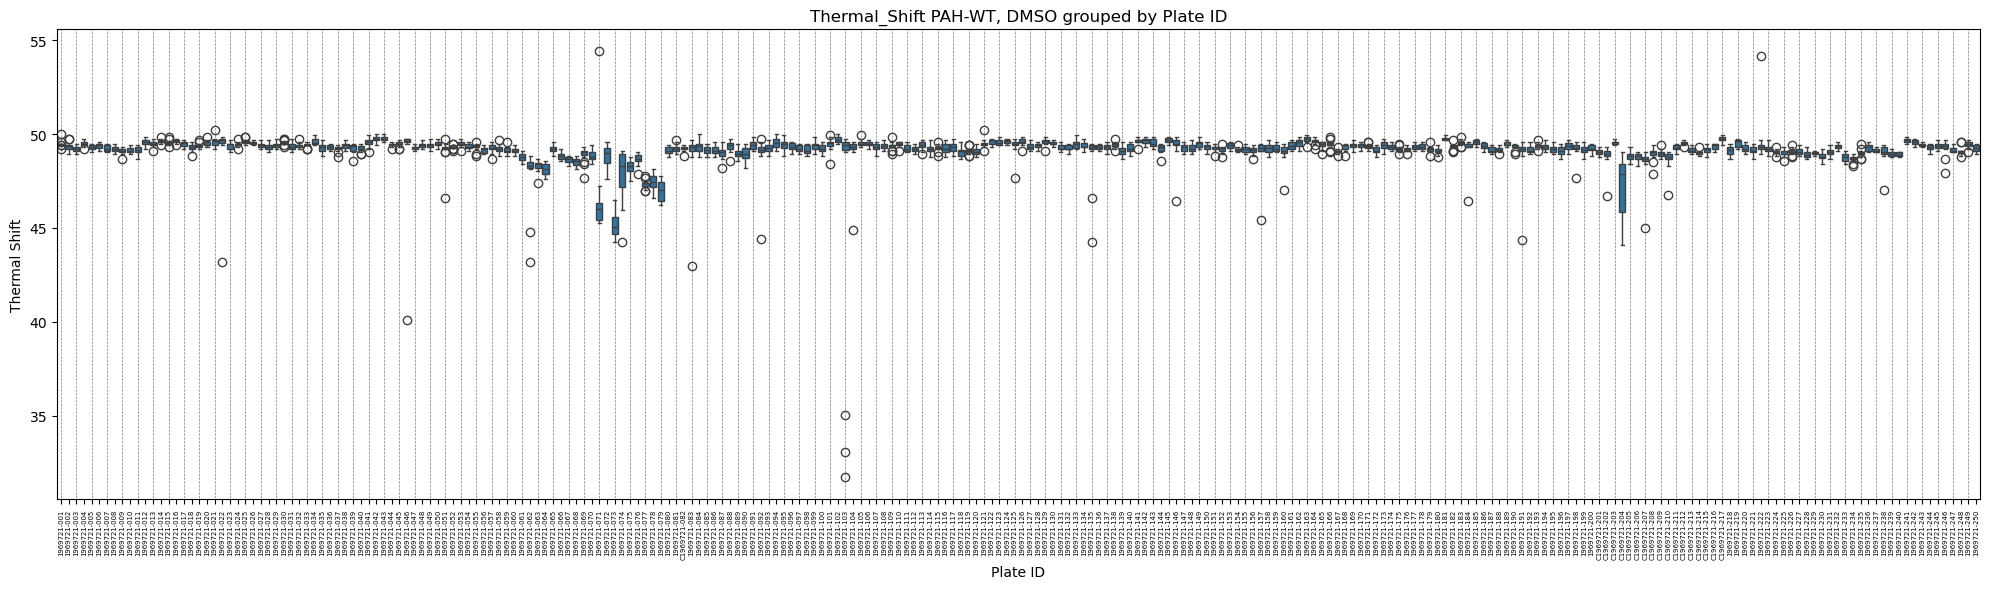

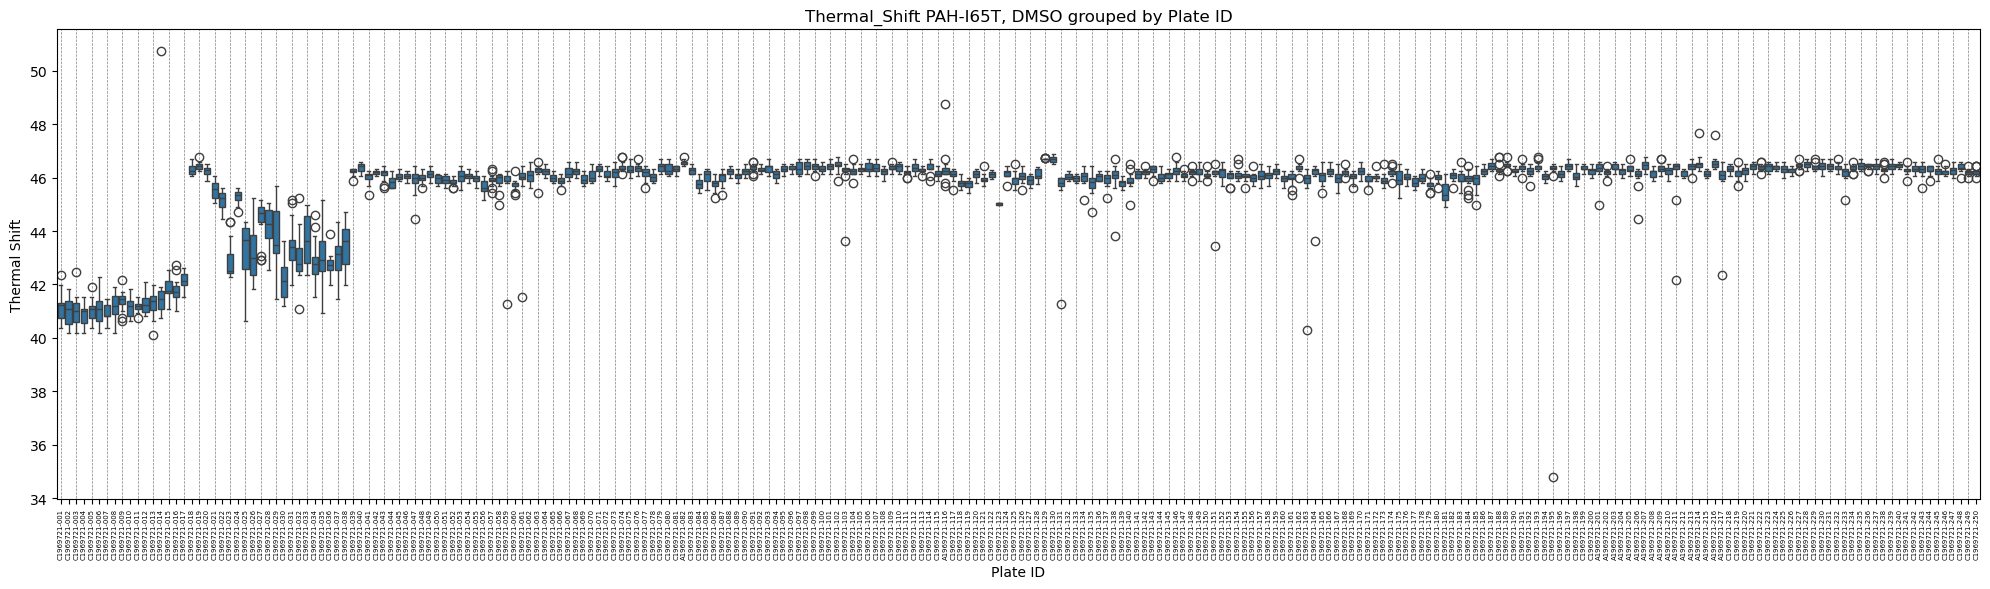

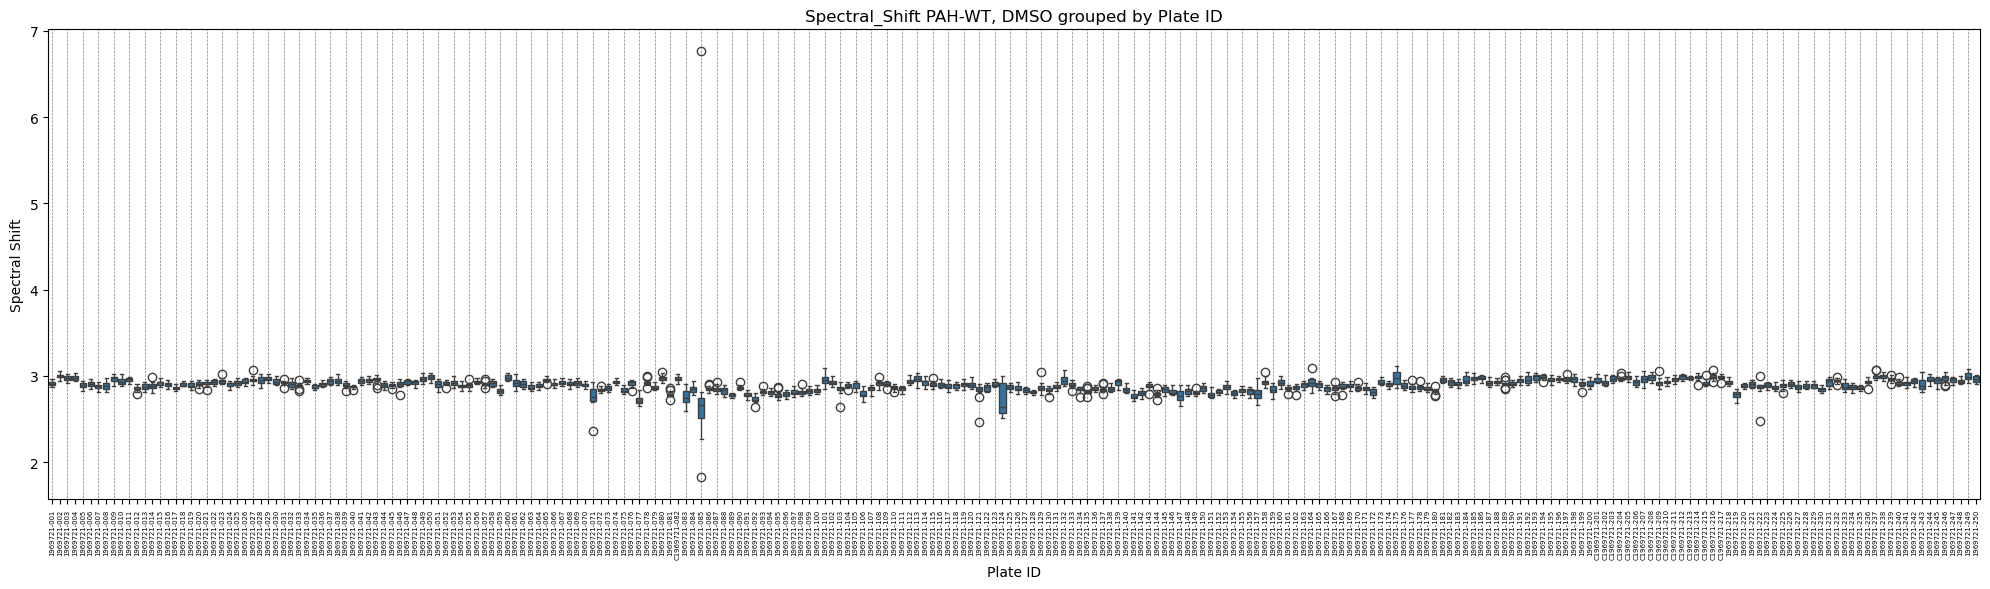

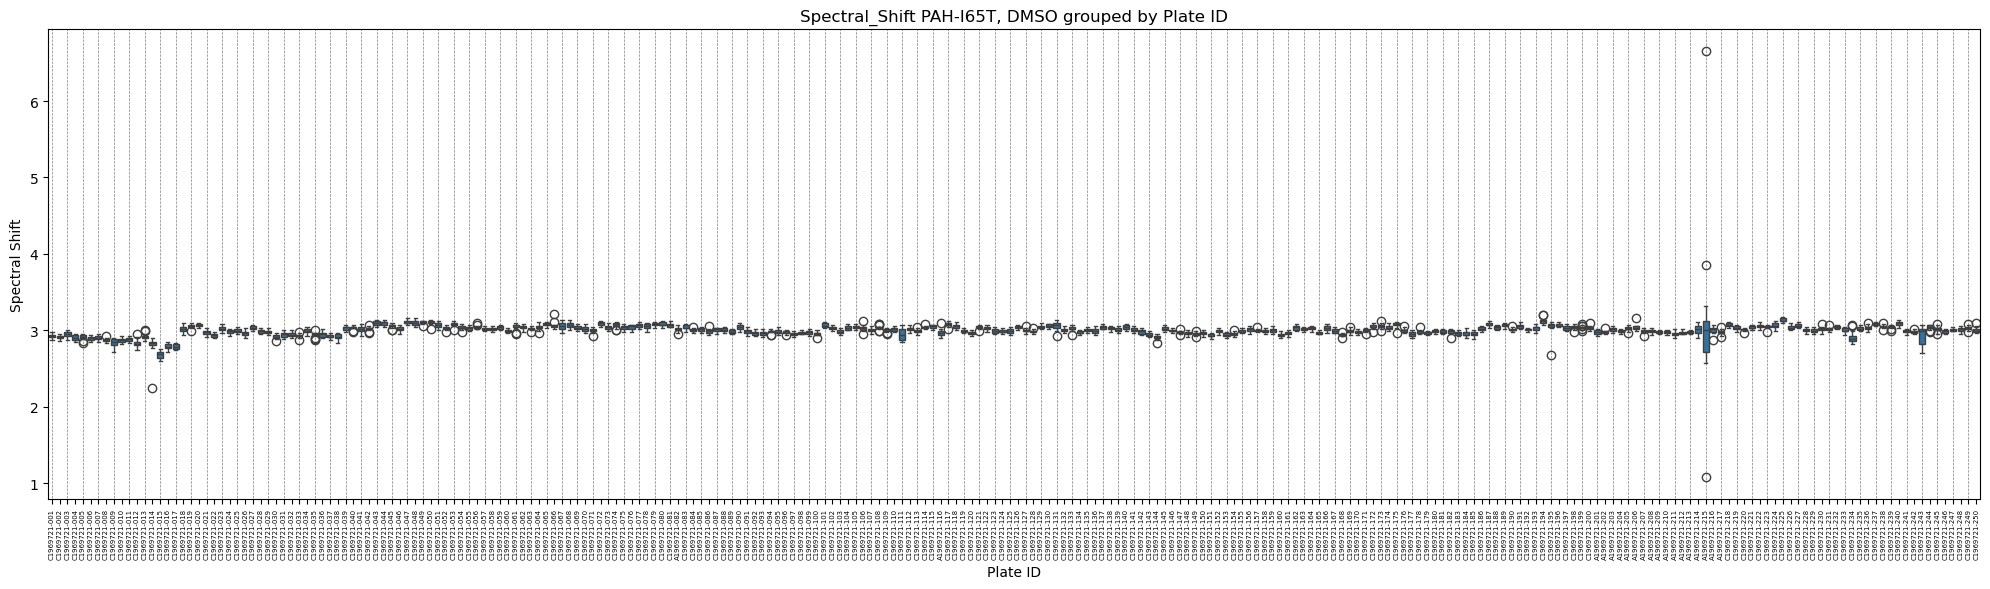

In [11]:
# Plot before outlier removal

boxplot_per_plate(df_ctrl, 
                  assey = 'Thermal_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assey = 'Thermal_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assey = 'Spectral_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assey = 'Spectral_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

In [12]:
# Detect outliers
df_qc = (
    df_ctrl
    .groupby('Plate_ID_cat', observed=True)
    .agg({
        'Protein': 'first',
        'Thermal_Shift': ['median', iqr],
        'Spectral_Shift': ['median', iqr]
    })
)
df_qc.columns = ['Protein', 'TSA_median', 'TSA_range', 'SpSh_median', 'SpSh_range']
df_qc.head()

,Protein,TSA_median,TSA_range,SpSh_median,SpSh_range
Plate_ID_cat,,,,,
1969721-001,PAH-WT,49.4840,0.000000,2.903465,0.031402
C1969721-001,PAH-I65T,41.2325,0.563625,2.919414,0.030101
C1969721-002,PAH-I65T,41.0972,0.856700,2.916621,0.033232
1969721-002,PAH-WT,49.3487,0.180400,3.001054,0.034008
1969721-003,PAH-WT,49.2134,0.180400,2.976828,0.049121


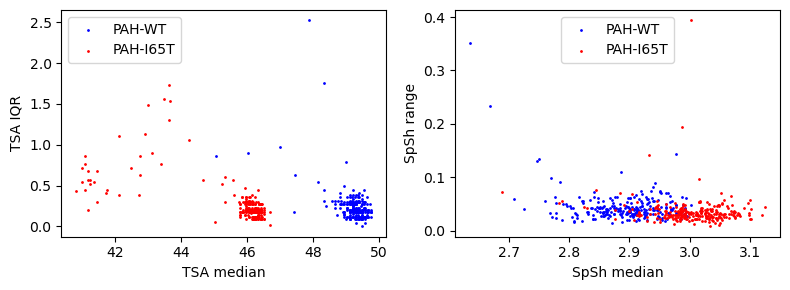

In [13]:
fig, ax = plt.subplots(1, 2, figsize=(8, 3))

# First subplot (TSA)
ax[0].scatter(df_qc.loc[df_qc['Protein'] == 'PAH-WT', 'TSA_median'], 
              df_qc.loc[df_qc['Protein'] == 'PAH-WT', 'TSA_range'],
              s=1, color='blue', label='PAH-WT')
ax[0].scatter(df_qc.loc[df_qc['Protein'] == 'PAH-I65T', 'TSA_median'], 
              df_qc.loc[df_qc['Protein'] == 'PAH-I65T', 'TSA_range'],
              s=1, color='red', label='PAH-I65T')
ax[0].set_xlabel('TSA median')
ax[0].set_ylabel('TSA IQR')
ax[0].legend()

# Second subplot (SpSh)
ax[1].scatter(df_qc.loc[df_qc['Protein'] == 'PAH-WT', 'SpSh_median'], 
              df_qc.loc[df_qc['Protein'] == 'PAH-WT', 'SpSh_range'],
              s=1, color='blue', label='PAH-WT')
ax[1].scatter(df_qc.loc[df_qc['Protein'] == 'PAH-I65T', 'SpSh_median'], 
              df_qc.loc[df_qc['Protein'] == 'PAH-I65T', 'SpSh_range'],
              s=1, color='red', label='PAH-I65T')
ax[1].set_xlabel('SpSh median')
ax[1].set_ylabel('SpSh range')
ax[1].legend()

plt.tight_layout()
plt.show()


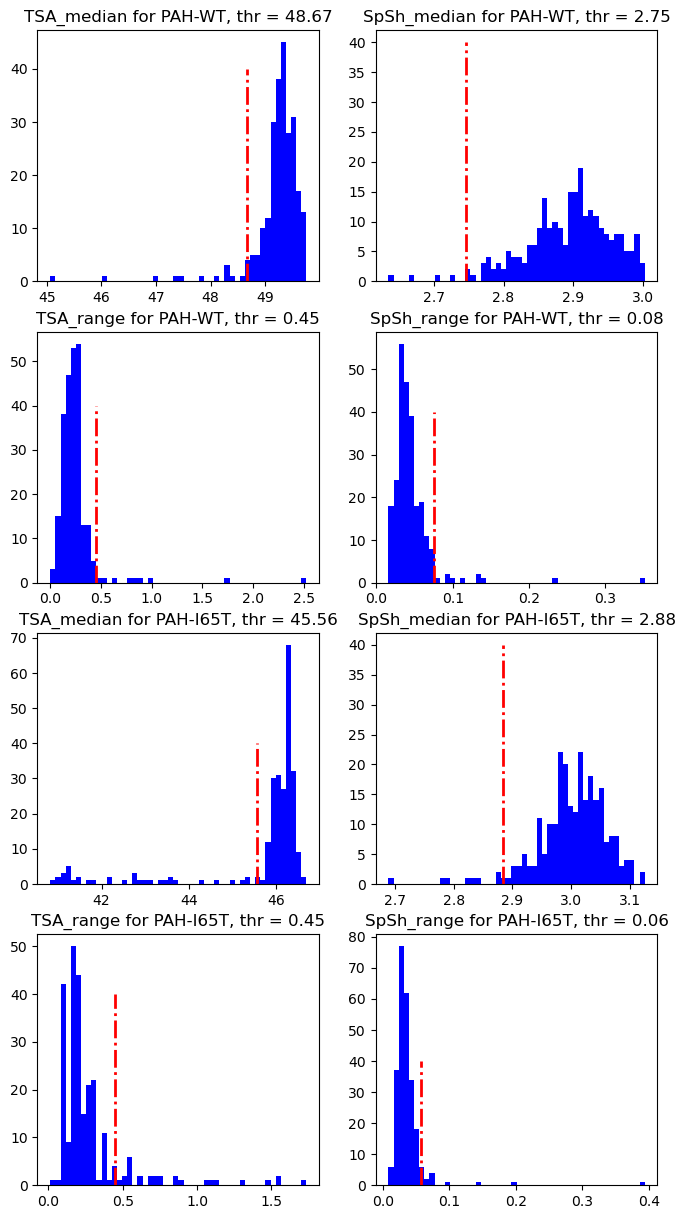

In [14]:
# Remove plates based on mean and IQR method
plot_outlier = []

fig, ax = plt.subplots(4, 2, figsize=(8, 15))
ax = ax.flatten()

i = 0
for prot in ['PAH-WT', 'PAH-I65T']:
    for col in ['TSA_median', 'SpSh_median', 'TSA_range', 'SpSh_range']:
        df_tmp = df_qc.loc[df_qc['Protein'] == prot].copy()
        thr = remove_outlayer(np.array(df_tmp[col]), method='iqr', return_bin=False)

        if col.split('_')[1] in ['median', 'mean']:
            thr = thr.min()
            plot_outlier.extend(list(df_tmp.loc[df_tmp[col] < thr].index))
        else:
            thr = thr.max()
            plot_outlier.extend(list(df_tmp.loc[df_tmp[col] > thr].index))
        
        ax[i].hist(df_tmp[col], 50, color='blue');
        ax[i].vlines(thr, ymin=0, ymax=40, colors='red', linestyles='-.', linewidth=2)
        ax[i].set_title(f'{col} for {prot}, thr = {thr:.2f}');
        i += 1

In [15]:
len(plot_outlier)

117

In [16]:
df_outlier_removed = df.loc[~df['Plate_ID'].isin(plot_outlier)].copy()
df_outlier_removed.shape

(147192, 38)

In [17]:
ctrl_id = 'DMSO'
df_ctrl = df_outlier_removed.loc[df_outlier_removed['ID'] == ctrl_id].copy()
df_other = df_outlier_removed.loc[df_outlier_removed['ID'] != ctrl_id].copy()

In [18]:
# Remove DMSO outlayer

print(df_ctrl.shape)

df_ctrl = remove_outlayer_df(df_ctrl, 
                             assey = 'Thermal_Shift', 
                             method = 'iqr'
                            )
df_ctrl = remove_outlayer_df(df_ctrl, 
                             assey = 'Spectral_Shift', 
                             method = 'iqr'
                            )
print(df_ctrl.shape)


(6886, 38)
(6346, 38)


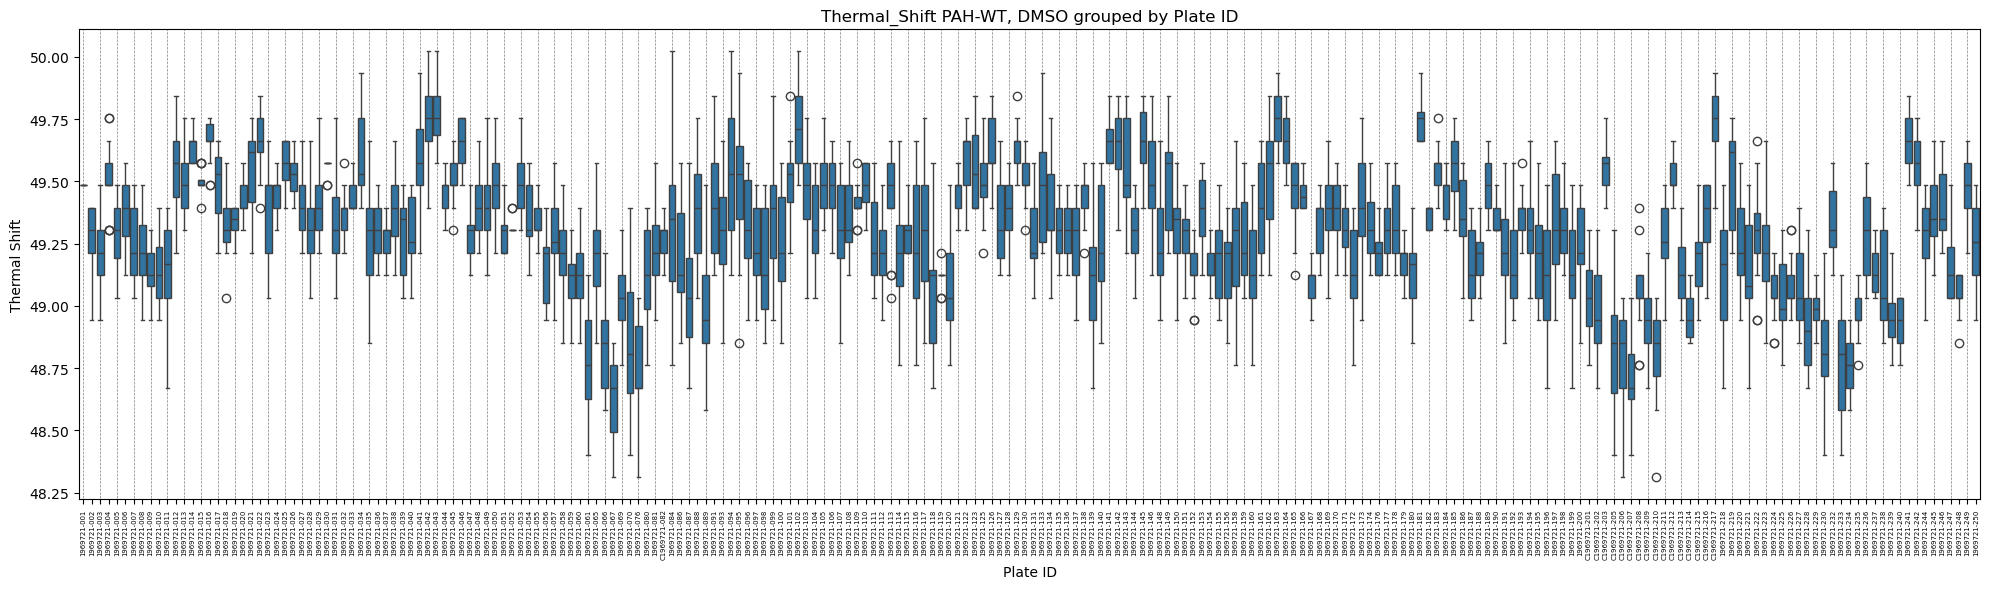

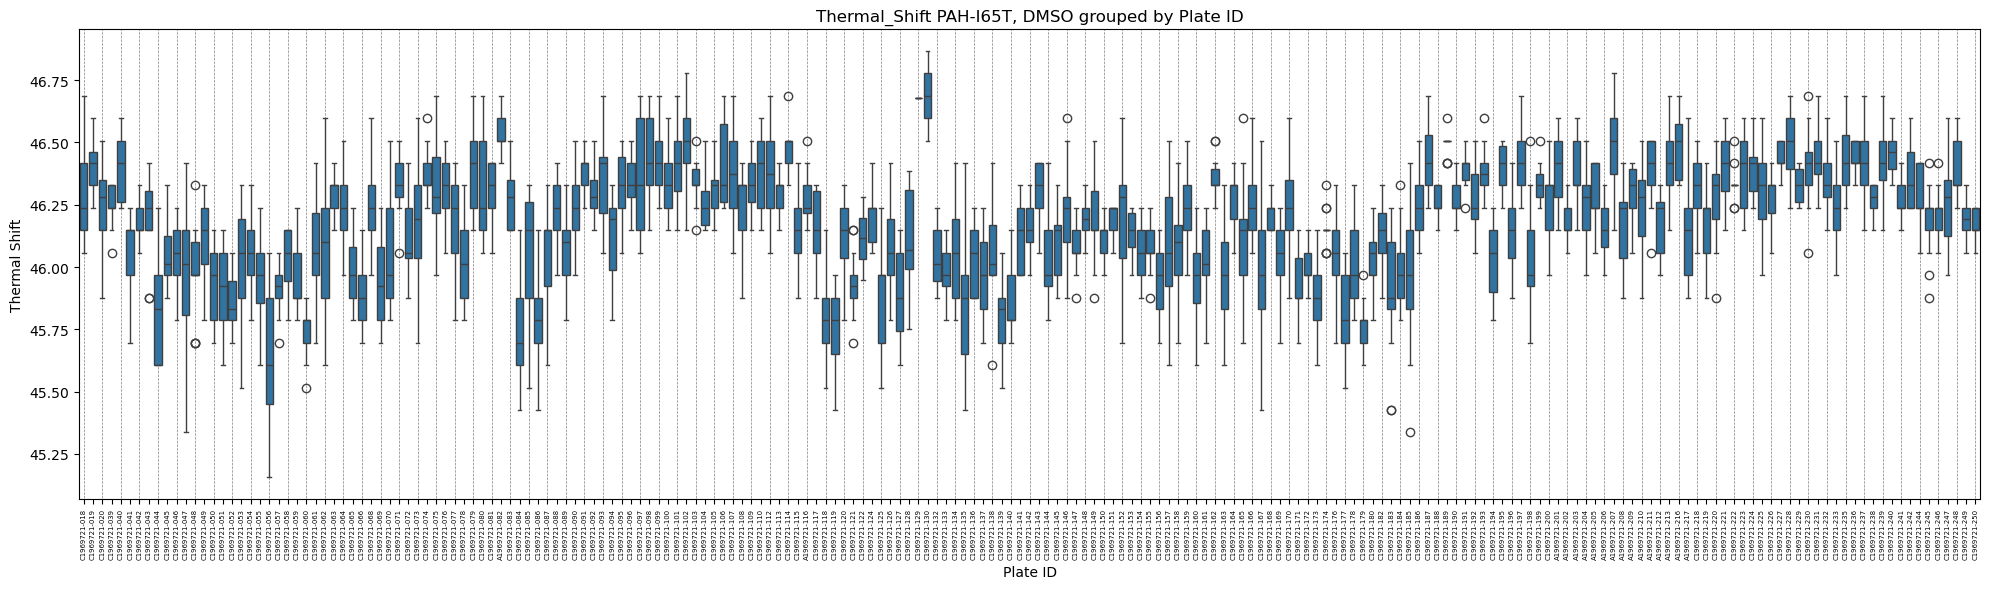

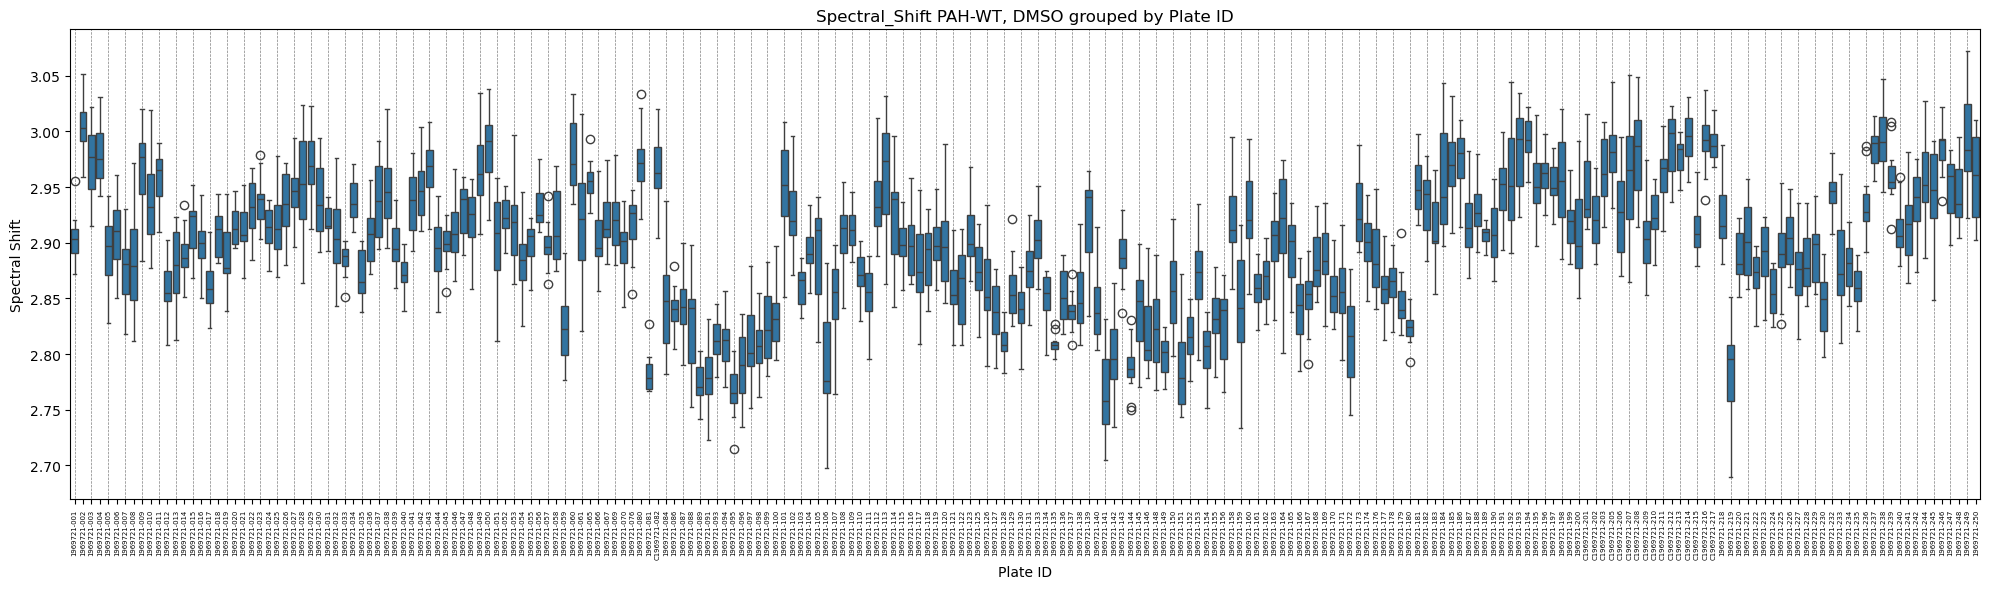

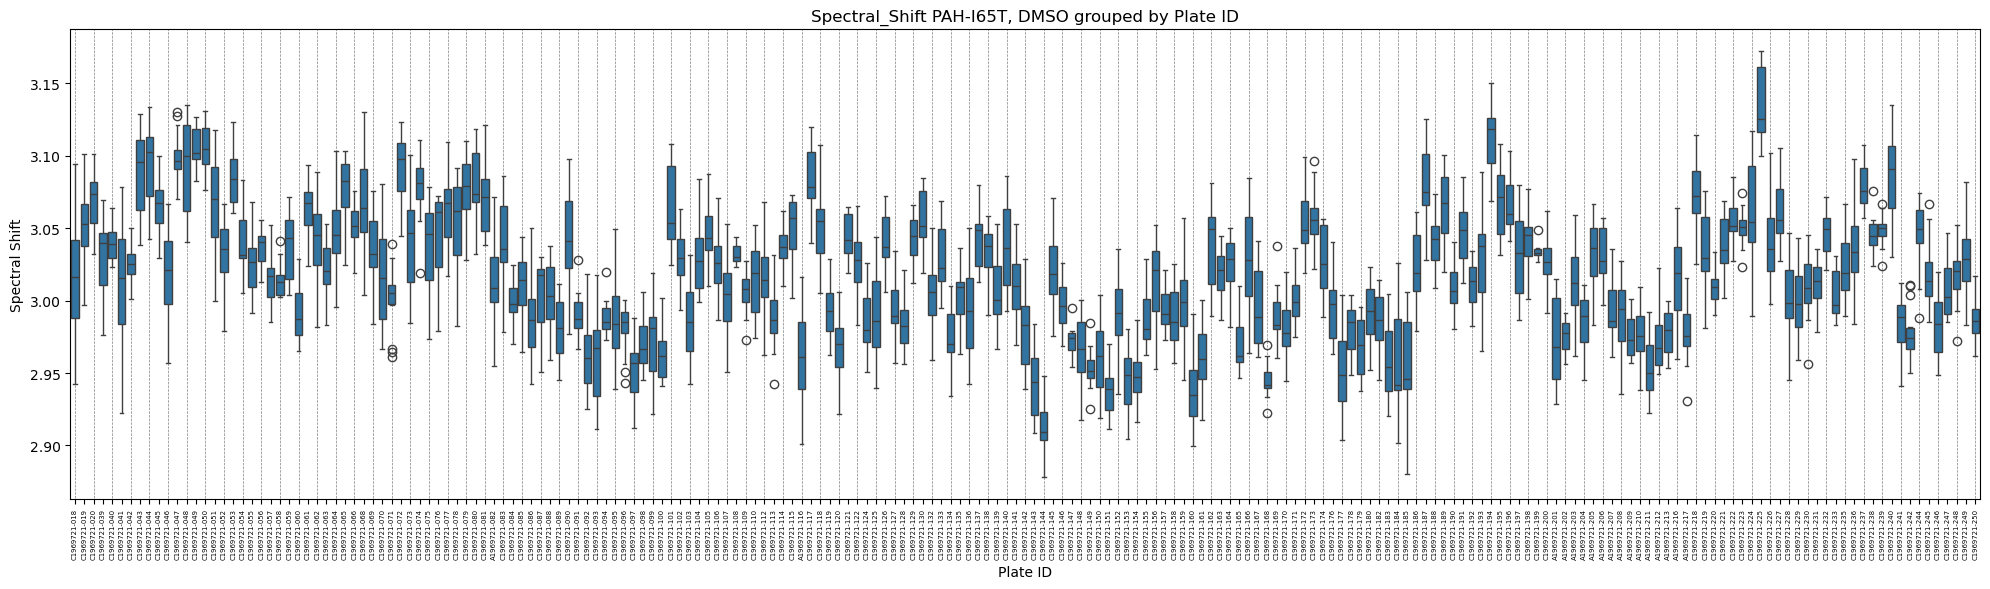

In [19]:
# Plot after outlier removal

boxplot_per_plate(df_ctrl, 
                  assey = 'Thermal_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assey = 'Thermal_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assey = 'Spectral_Shift', 
                  protein = 'PAH-WT', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

boxplot_per_plate(df_ctrl, 
                  assey = 'Spectral_Shift', 
                  protein = 'PAH-I65T', 
                  title='DMSO grouped by Plate ID', 
                  save_dir=None
                 )

In [20]:
sd_other = df_other.groupby('Plate_ID')['Thermal_Shift'].agg(iqr)
sd_crtl = df_ctrl.groupby('Plate_ID')['Thermal_Shift'].agg(iqr)
sd_other = np.array(sd_other)
sd_crtl = np.array(sd_crtl)

np.corrcoef(sd_other, sd_crtl)[0, 1], np.std(sd_other)

(np.float64(0.2196128677580192), np.float64(0.06514107432657353))

In [21]:
assey = ['Thermal_Shift', 'Spectral_Shift'][1]
sd_other = df_other.groupby('Plate_ID')['Spectral_Shift'].agg(iqr)
sd_crtl = df_ctrl.groupby('Plate_ID')['Spectral_Shift'].agg(iqr)
sd_other = np.array(sd_other)
sd_crtl = np.array(sd_crtl)

np.corrcoef(sd_other, sd_crtl)[0, 1], np.std(sd_other)

(np.float64(0.36095673818546015), np.float64(0.010229178480338805))

In [22]:
# Normalise
assey = ['Thermal_Shift', 'Spectral_Shift'][0]
method = ['zscore', 'quantile'][1]

df_outlier_removed[f'norm_{assey}'] = None
for i in df_outlier_removed['Plate_ID'].unique():
    x = df_other.loc[df_other['Plate_ID'] == i, assey]
    control = df_ctrl.loc[df_ctrl['Plate_ID'] == i, assey]
    
    x = normalize(x, control, method=method, scale=False)
    df_other.loc[df_other['Plate_ID'] == i, f'norm_{assey}'] = x
    
    x = normalize(control, control, method=method, scale=False)
    df_ctrl.loc[df_ctrl['Plate_ID'] == i, f'norm_{assey}'] = x

# Normalise
assey = ['Thermal_Shift', 'Spectral_Shift'][1]
method = ['zscore', 'quantile'][1]

df_outlier_removed[f'norm_{assey}'] = None
for i in df_outlier_removed['Plate_ID'].unique():
    x = df_other.loc[df_other['Plate_ID'] == i, assey]
    control = df_ctrl.loc[df_ctrl['Plate_ID'] == i, assey]
    
    x = normalize(x, control, method=method, scale=False)
    df_other.loc[df_other['Plate_ID'] == i, f'norm_{assey}'] = x
    
    x = normalize(control, control, method=method, scale=False)
    df_ctrl.loc[df_ctrl['Plate_ID'] == i, f'norm_{assey}'] = x

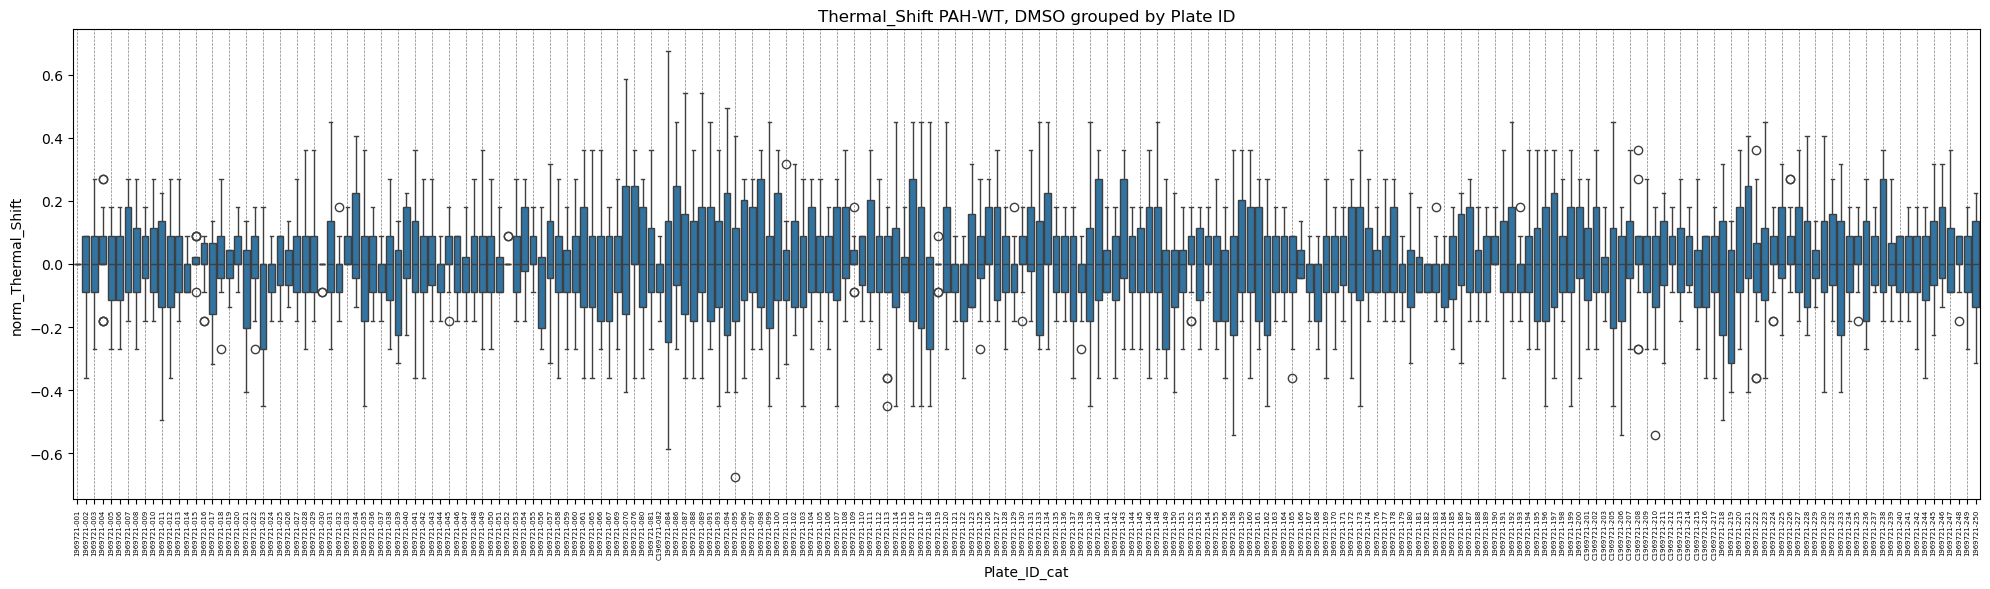

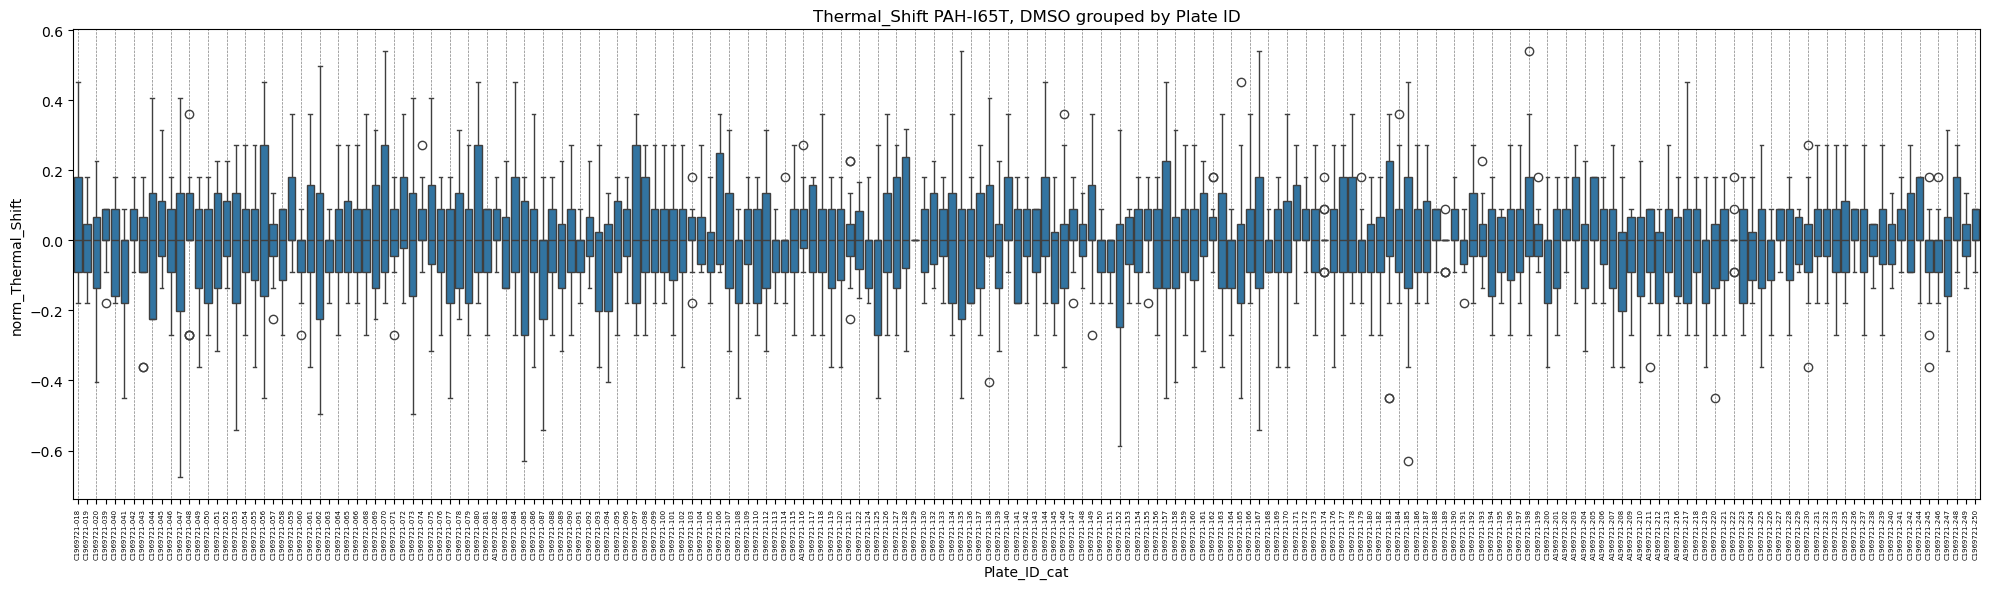

In [23]:
assey = ['Thermal_Shift', 'Spectral_Shift'][0]

# Plate-id orderes: 
# to see original order use Plate_ID
# to see them ordered based on numbers use Plate_ID_cat

# Restrict to a protein
# PAH-WT
plt.figure(figsize=(20, 6))

df_ctrl_prot = df_ctrl.loc[df_ctrl['Protein'] == 'PAH-WT'].copy()
df_ctrl_prot['Plate_ID_cat'] = df_ctrl_prot['Plate_ID_cat'].cat.remove_unused_categories()

n_plate = len(df_ctrl_prot['Plate_ID_cat'].unique())
plt.vlines(np.arange(0, n_plate, 2), ymin = -10, ymax = 10, colors='gray', linestyles='dashed', linewidth=0.5)
sns.boxplot(data=df_ctrl_prot, x='Plate_ID_cat', y=f'norm_{assey}')

plt.title(f'{assey} PAH-WT, DMSO grouped by Plate ID')
plt.xticks(rotation=90, size = 5)
plt.tight_layout()
# plt.savefig(f"data/plt_{assey}_DMSO_{save_tag}.pdf")
plt.show()
plt.close()

# Restrict to a protein
# PAH-I65T

plt.figure(figsize=(20, 6))

df_ctrl_prot = df_ctrl.loc[df_ctrl['Protein'] == 'PAH-I65T'].copy()
df_ctrl_prot['Plate_ID_cat'] = df_ctrl_prot['Plate_ID_cat'].cat.remove_unused_categories()

n_plate = len(df_ctrl_prot['Plate_ID_cat'].unique())
plt.vlines(np.arange(0, n_plate, 2), ymin = -10, ymax = 10, colors='gray', linestyles='dashed', linewidth=0.5)
sns.boxplot(data=df_ctrl_prot, x='Plate_ID_cat', y=f'norm_{assey}')

plt.title(f'{assey} PAH-I65T, DMSO grouped by Plate ID')
plt.xticks(rotation=90, size = 5)
plt.tight_layout()
# plt.savefig(f"data/plt_{assey}_I65T_DMSO_{save_tag}.pdf")
plt.show()
plt.close()

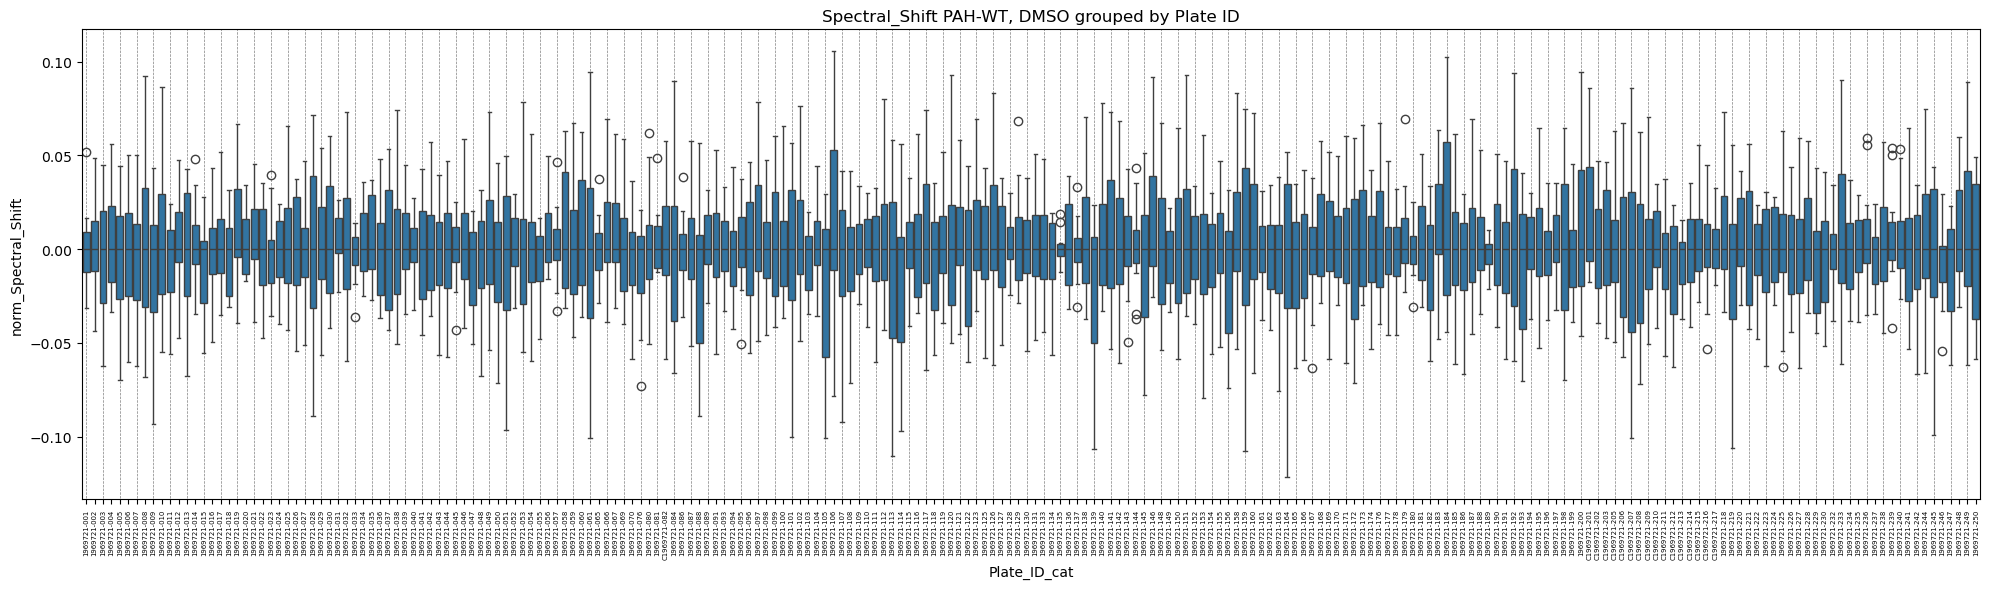

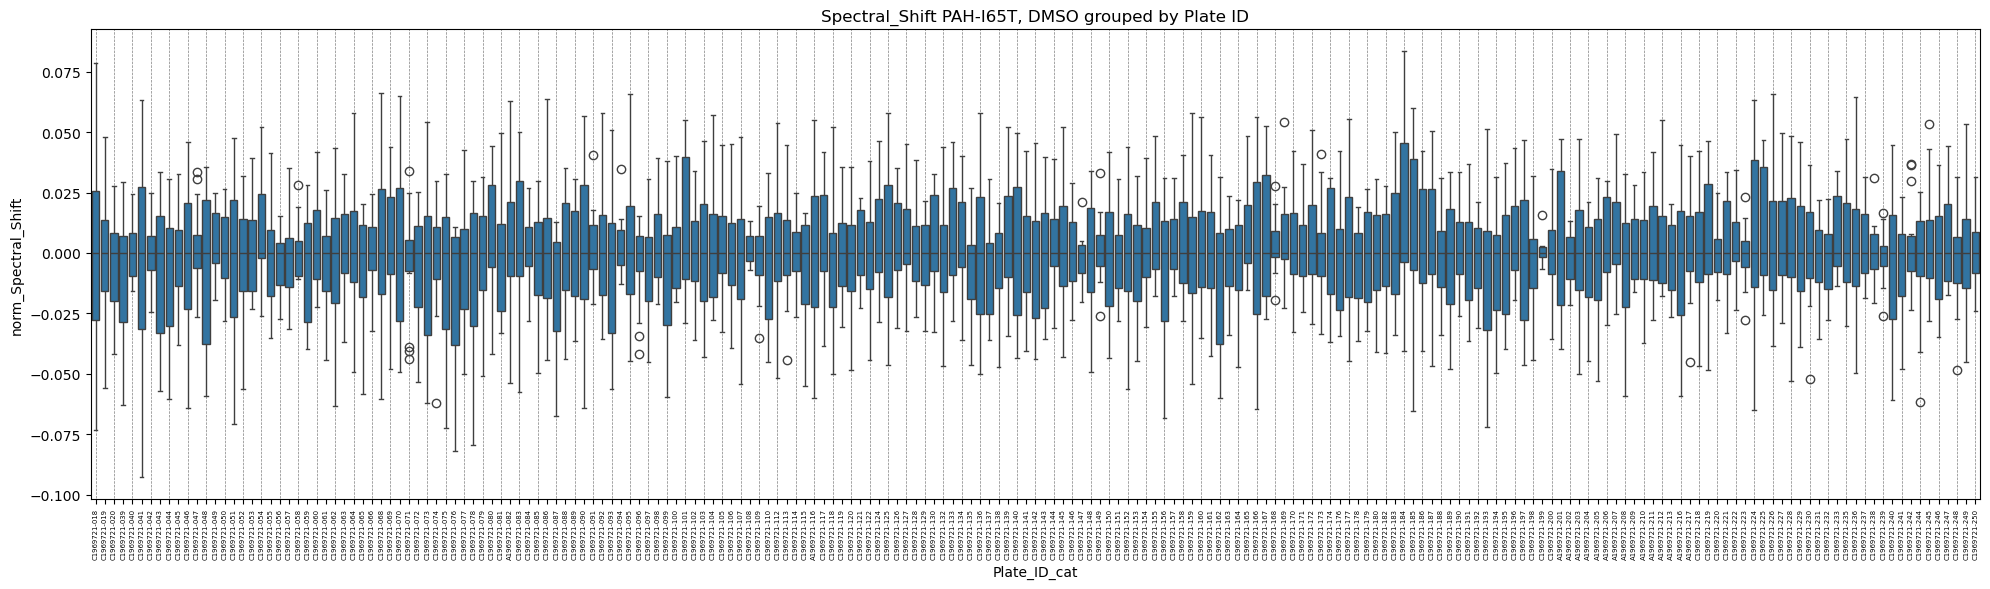

In [24]:
assey = ['Thermal_Shift', 'Spectral_Shift'][1]

# Plate-id orderes: 
# to see original order use Plate_ID
# to see them ordered based on numbers use Plate_ID_cat

# Restrict to a protein
# PAH-WT
plt.figure(figsize=(20, 6))

df_ctrl_prot = df_ctrl.loc[df_ctrl['Protein'] == 'PAH-WT'].copy()
df_ctrl_prot['Plate_ID_cat'] = df_ctrl_prot['Plate_ID_cat'].cat.remove_unused_categories()

n_plate = len(df_ctrl_prot['Plate_ID_cat'].unique())
plt.vlines(np.arange(0, n_plate, 2), ymin = -10, ymax = 10, colors='gray', linestyles='dashed', linewidth=0.5)
sns.boxplot(data=df_ctrl_prot, x='Plate_ID_cat', y=f'norm_{assey}')

plt.title(f'{assey} PAH-WT, DMSO grouped by Plate ID')
plt.xticks(rotation=90, size = 5)
plt.tight_layout()
# plt.savefig(f"data/plt_{assey}_DMSO_{save_tag}.pdf")
plt.show()
plt.close()

# Restrict to a protein
# PAH-I65T

plt.figure(figsize=(20, 6))

df_ctrl_prot = df_ctrl.loc[df_ctrl['Protein'] == 'PAH-I65T'].copy()
df_ctrl_prot['Plate_ID_cat'] = df_ctrl_prot['Plate_ID_cat'].cat.remove_unused_categories()

n_plate = len(df_ctrl_prot['Plate_ID_cat'].unique())
plt.vlines(np.arange(0, n_plate, 2), ymin = -10, ymax = 10, colors='gray', linestyles='dashed', linewidth=0.5)
sns.boxplot(data=df_ctrl_prot, x='Plate_ID_cat', y=f'norm_{assey}')

plt.title(f'{assey} PAH-I65T, DMSO grouped by Plate ID')
plt.xticks(rotation=90, size = 5)
plt.tight_layout()
# plt.savefig(f"data/plt_{assey}_I65T_DMSO_{save_tag}.pdf")
plt.show()
plt.close()

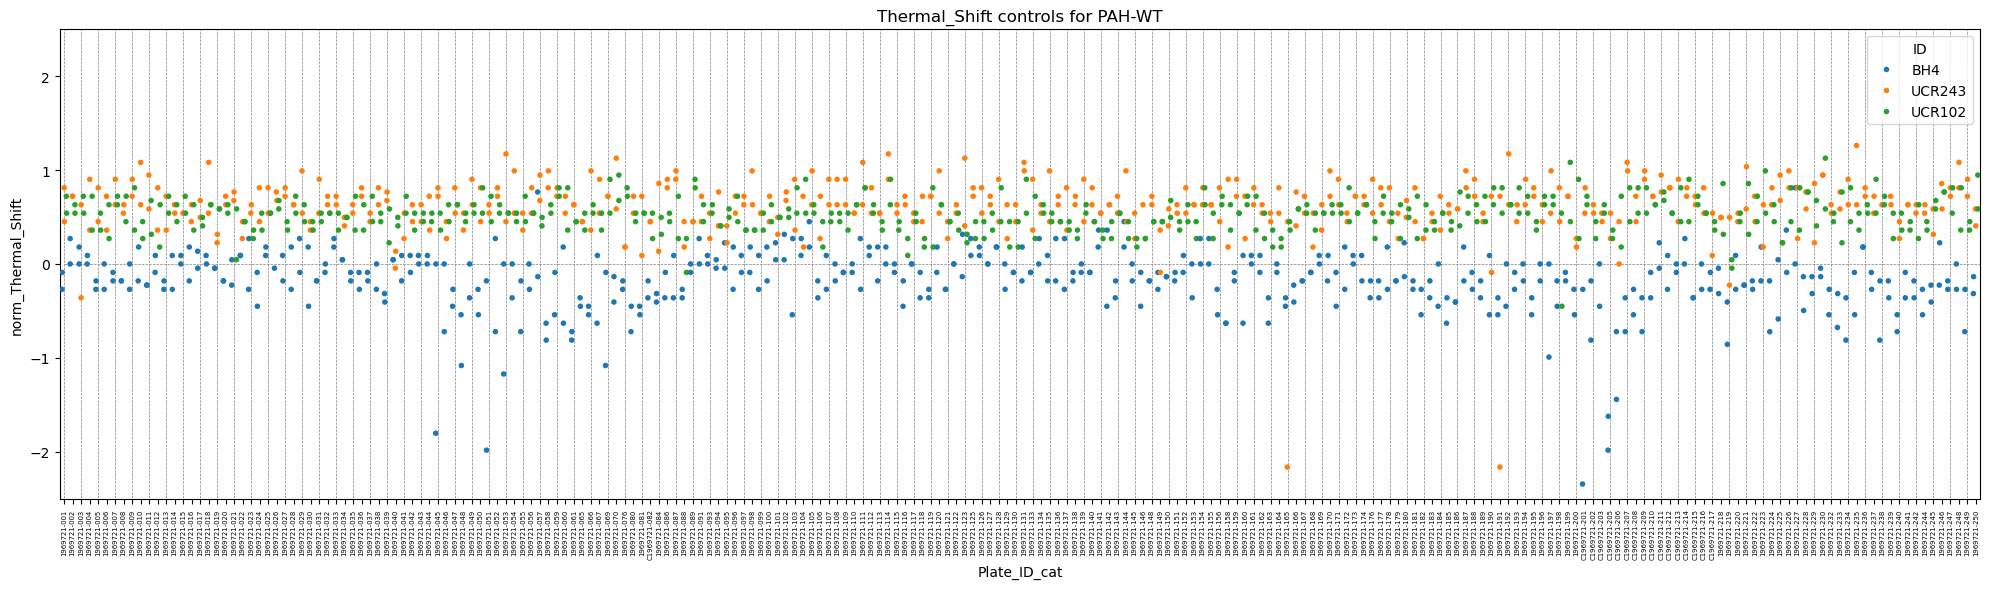

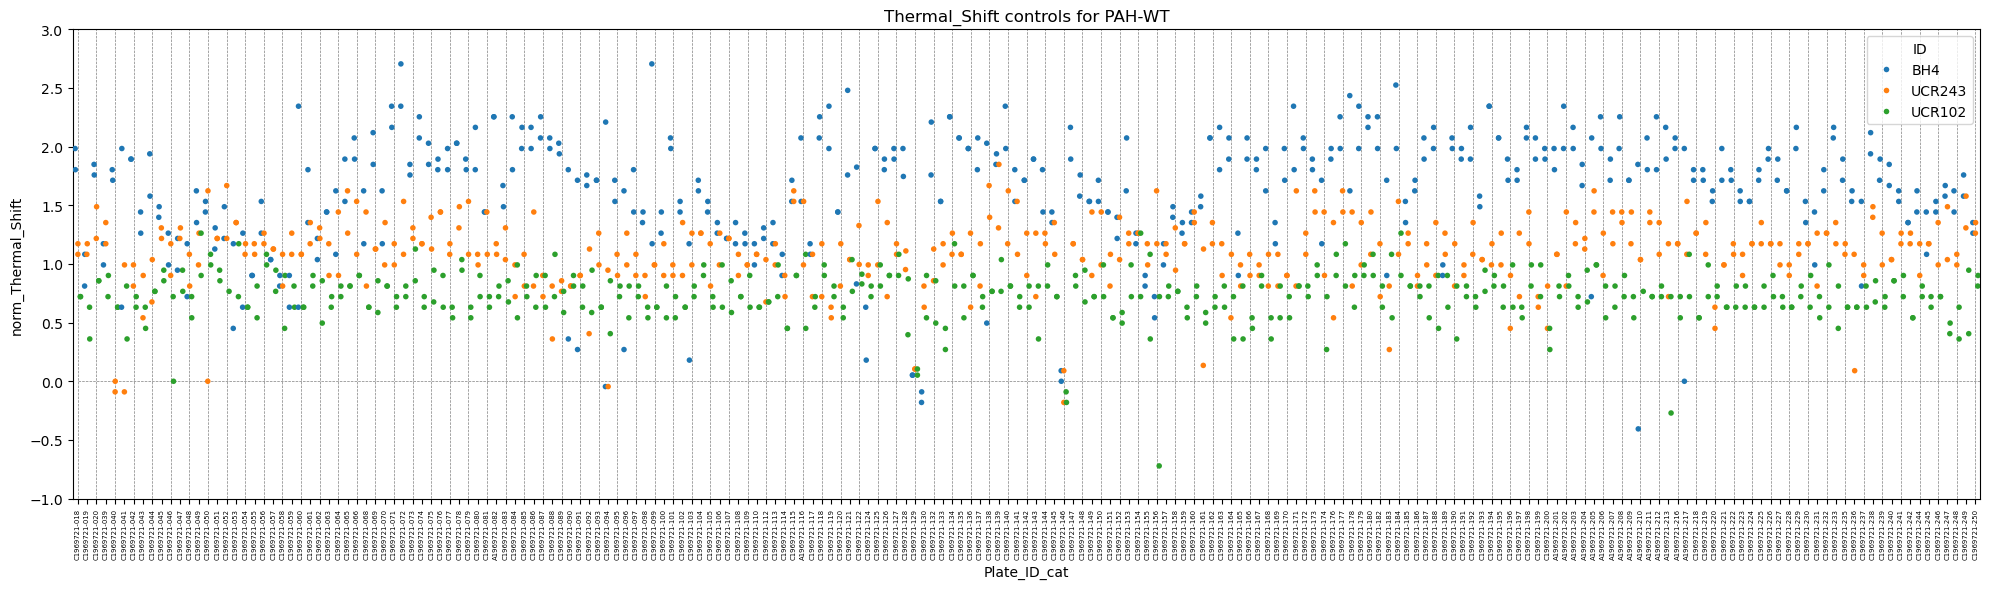

In [25]:
# Show controls only
assey = ['Thermal_Shift', 'Spectral_Shift'][0]

plt.figure(figsize=(20, 6))

df_other_prot = df_other.loc[df_other['Protein'] == 'PAH-WT'].copy()
df_other_prot['Plate_ID_cat'] = df_other_prot['Plate_ID_cat'].cat.remove_unused_categories()

n_plate = len(df_other_prot['Plate_ID_cat'].unique())

df_other_control = df_other_prot.loc[df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])]

plt.vlines(np.arange(0, n_plate, 2), ymin = -30, ymax = 30, colors='gray', linestyles='dashed', linewidth=0.5)
plt.hlines(0, xmin = 0, xmax = n_plate, colors='gray', linestyles='dashed', linewidth=0.5)

sns.stripplot(data=df_other_control, x='Plate_ID_cat', y=f'norm_{assey}', hue='ID', dodge=True, jitter=True, size=4)

plt.title(f'{assey} controls for PAH-WT')
plt.xticks(rotation=90, size = 5)
# plt.ylim([-30, 30])
plt.ylim([-2.5, 2.5])
plt.tight_layout()
# plt.savefig(f"data/plt_{assey}_control_norm_{save_tag}_PAH_WT.pdf")
plt.show()
plt.close()

# Show controls only
plt.figure(figsize=(20, 6))

df_other_prot = df_other.loc[df_other['Protein'] == 'PAH-I65T'].copy()
df_other_prot['Plate_ID_cat'] = df_other_prot['Plate_ID_cat'].cat.remove_unused_categories()

n_plate = len(df_other_prot['Plate_ID_cat'].unique())

df_other_control = df_other_prot.loc[df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])]

plt.vlines(np.arange(0, n_plate, 2), ymin = -30, ymax = 30, colors='gray', linestyles='dashed', linewidth=0.5)
plt.hlines(0, xmin = 0, xmax = n_plate, colors='gray', linestyles='dashed', linewidth=0.5)

sns.stripplot(data=df_other_control, x='Plate_ID_cat', y=f'norm_{assey}', hue='ID', dodge=True, jitter=True, size=4)

plt.title(f'{assey} controls for PAH-WT')
plt.xticks(rotation=90, size = 5)
# plt.ylim([-30, 30])
plt.ylim([-1, 3])
plt.tight_layout()
# plt.savefig(f"data/plt_{assey}_control_norm_{save_tag}_PAH_WT.pdf")
plt.show()
plt.close()

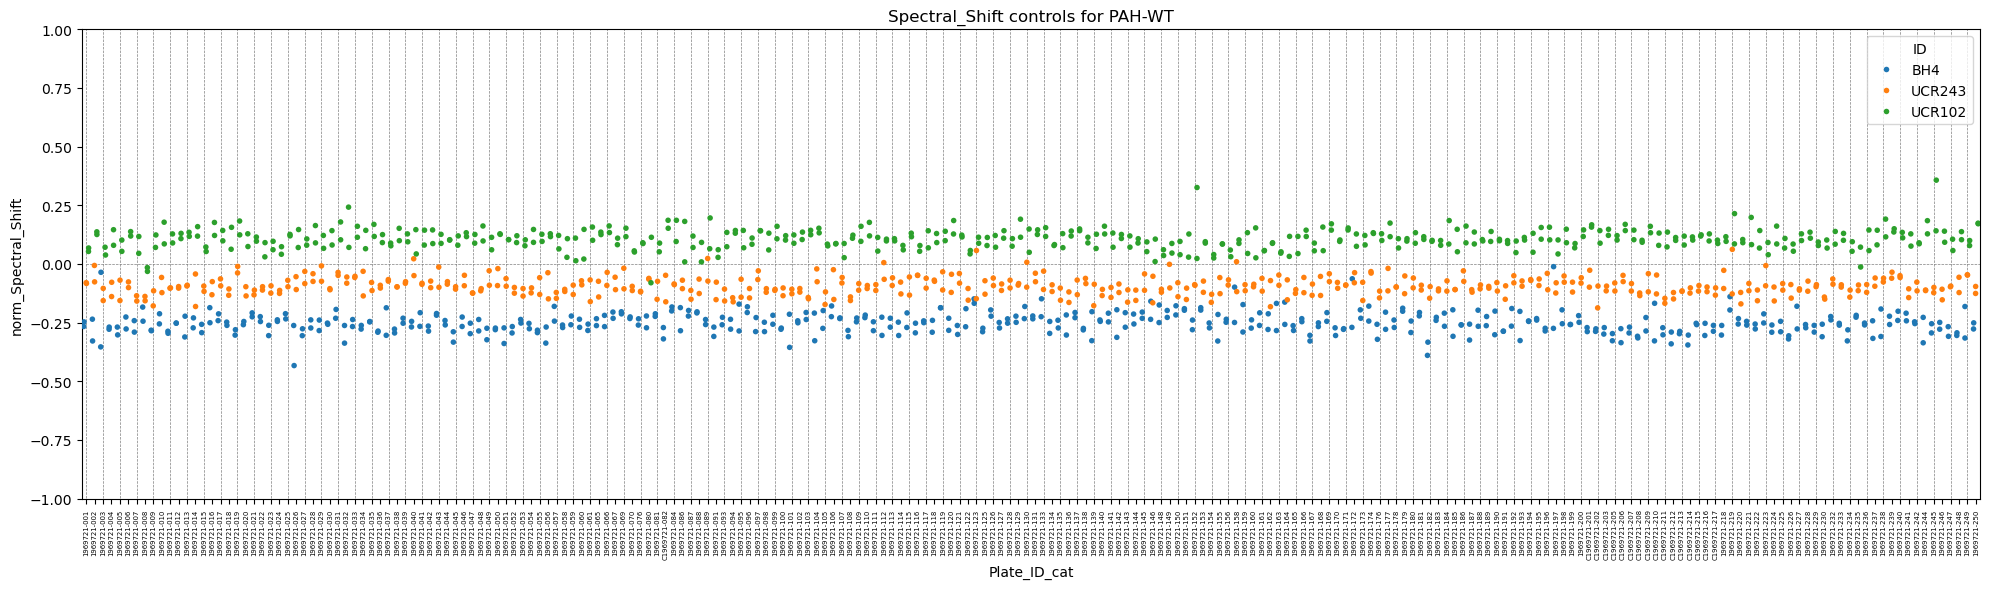

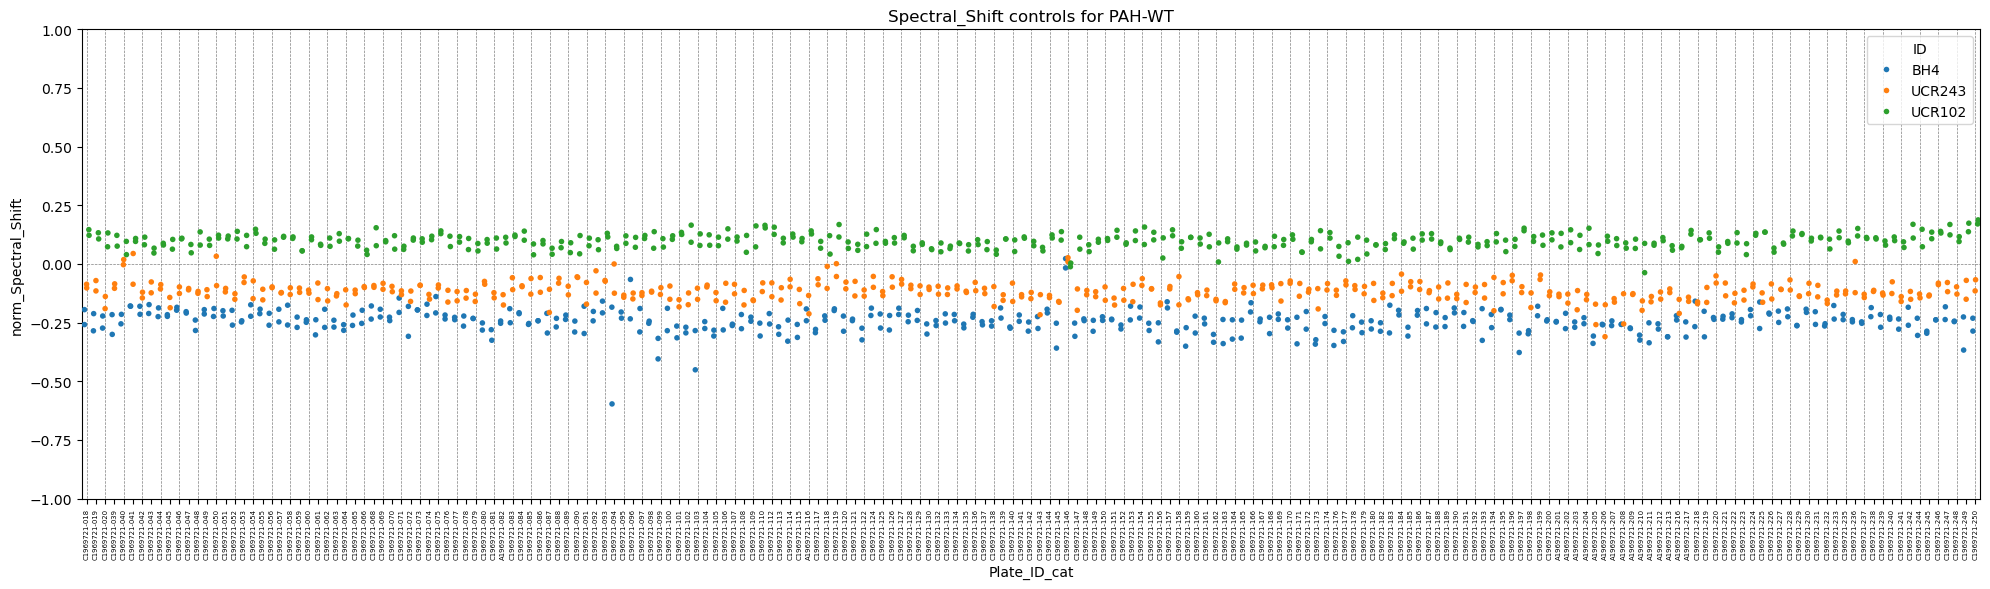

In [26]:
# Show controls only
assey = ['Thermal_Shift', 'Spectral_Shift'][1]

plt.figure(figsize=(20, 6))

df_other_prot = df_other.loc[df_other['Protein'] == 'PAH-WT'].copy()
df_other_prot['Plate_ID_cat'] = df_other_prot['Plate_ID_cat'].cat.remove_unused_categories()

n_plate = len(df_other_prot['Plate_ID_cat'].unique())

df_other_control = df_other_prot.loc[df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])]

plt.vlines(np.arange(0, n_plate, 2), ymin = -30, ymax = 30, colors='gray', linestyles='dashed', linewidth=0.5)
plt.hlines(0, xmin = 0, xmax = n_plate, colors='gray', linestyles='dashed', linewidth=0.5)

sns.stripplot(data=df_other_control, x='Plate_ID_cat', y=f'norm_{assey}', hue='ID', dodge=True, jitter=True, size=4)

plt.title(f'{assey} controls for PAH-WT')
plt.xticks(rotation=90, size = 5)
# plt.ylim([-30, 30])
plt.ylim([-1, 1])
plt.tight_layout()
# plt.savefig(f"data/plt_{assey}_control_norm_{save_tag}_PAH_WT.pdf")
plt.show()
plt.close()

# Show controls only
plt.figure(figsize=(20, 6))

df_other_prot = df_other.loc[df_other['Protein'] == 'PAH-I65T'].copy()
df_other_prot['Plate_ID_cat'] = df_other_prot['Plate_ID_cat'].cat.remove_unused_categories()

n_plate = len(df_other_prot['Plate_ID_cat'].unique())

df_other_control = df_other_prot.loc[df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])]

plt.vlines(np.arange(0, n_plate, 2), ymin = -30, ymax = 30, colors='gray', linestyles='dashed', linewidth=0.5)
plt.hlines(0, xmin = 0, xmax = n_plate, colors='gray', linestyles='dashed', linewidth=0.5)

sns.stripplot(data=df_other_control, x='Plate_ID_cat', y=f'norm_{assey}', hue='ID', dodge=True, jitter=True, size=4)

plt.title(f'{assey} controls for PAH-WT')
plt.xticks(rotation=90, size = 5)
plt.ylim([-1, 1])
plt.tight_layout()
# plt.savefig(f"data/plt_{assey}_control_norm_{save_tag}_PAH_WT.pdf")
plt.show()
plt.close()

In [117]:
# Normalise
assey = ['Thermal_Shift', 'Spectral_Shift'][0]
method = ['zscore', 'quantile'][0]

df_outlier_removed[f'norm_{assey}'] = None
for i in df_outlier_removed['Plate_ID'].unique():
    x = df_other.loc[df_other['Plate_ID'] == i, assey]
    control = df_ctrl.loc[df_ctrl['Plate_ID'] == i, assey]
    
    x = normalize(x, control, method=method, scale=True)
    df_other.loc[df_other['Plate_ID'] == i, f'norm_{assey}'] = x
    
    x = normalize(control, control, method=method, scale=True)
    df_ctrl.loc[df_ctrl['Plate_ID'] == i, f'norm_{assey}'] = x


# Normalise
assey = ['Thermal_Shift', 'Spectral_Shift'][1]
method = ['zscore', 'quantile'][0]

df_outlier_removed[f'norm_{assey}'] = None
for i in df_outlier_removed['Plate_ID'].unique():
    x = df_other.loc[df_other['Plate_ID'] == i, assey]
    control = df_ctrl.loc[df_ctrl['Plate_ID'] == i, assey]
    
    x = normalize(x, control, method=method, scale=True)
    df_other.loc[df_other['Plate_ID'] == i, f'norm_{assey}'] = x
    
    x = normalize(control, control, method=method, scale=True)
    df_ctrl.loc[df_ctrl['Plate_ID'] == i, f'norm_{assey}'] = x


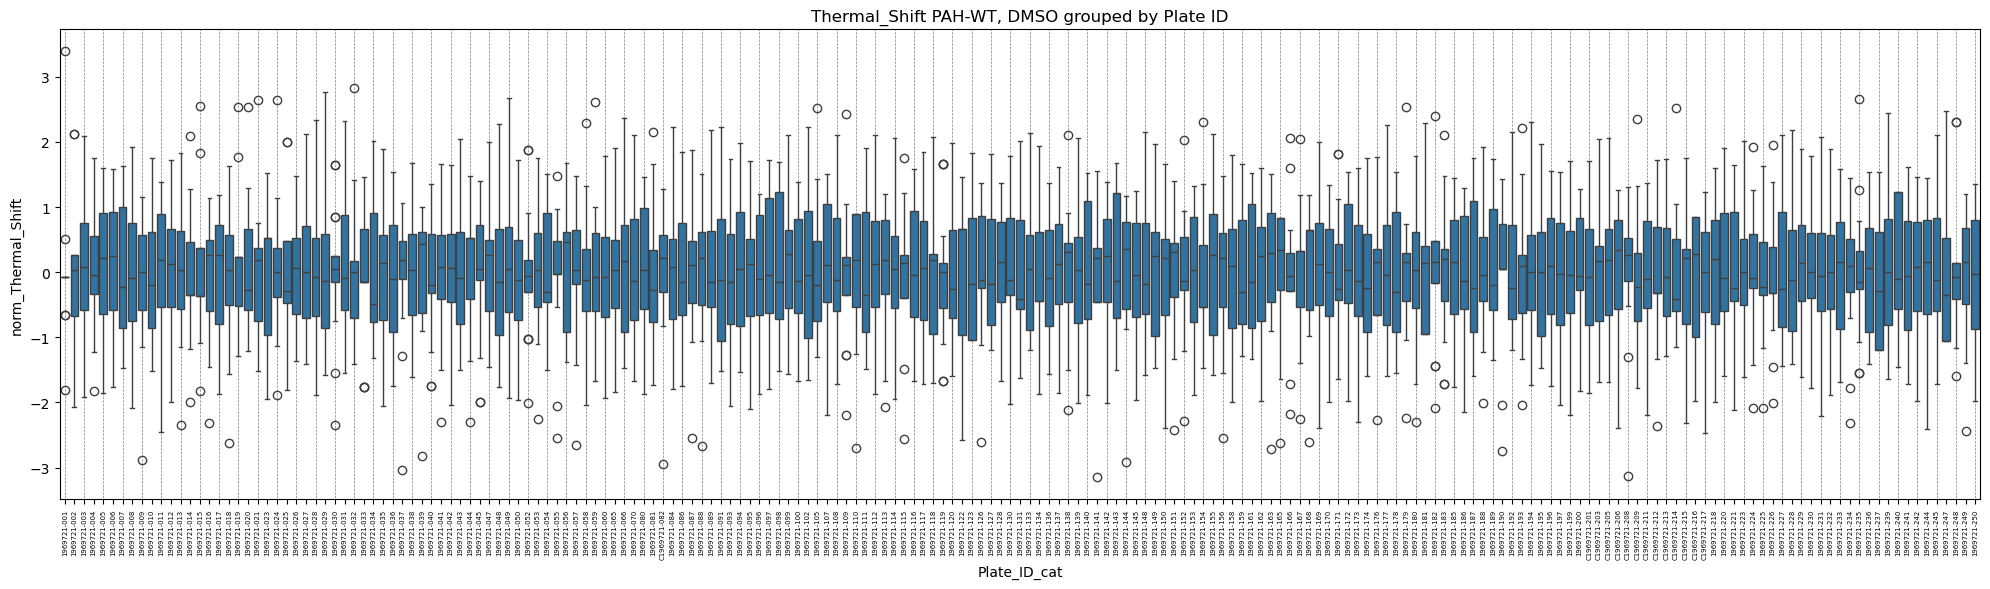

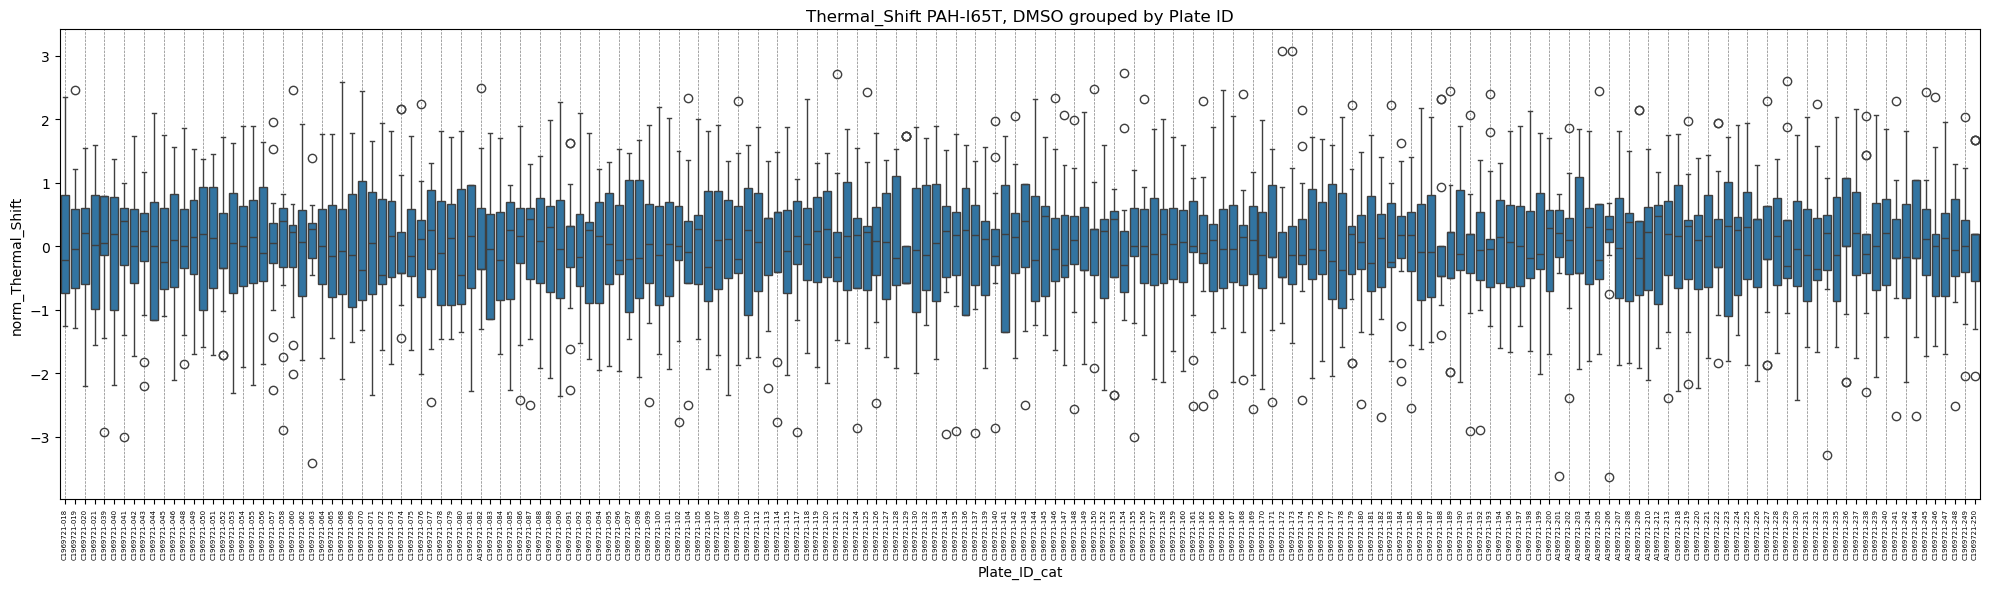

In [118]:
assey = ['Thermal_Shift', 'Spectral_Shift'][0]

# Plate-id orderes: 
# to see original order use Plate_ID
# to see them ordered based on numbers use Plate_ID_cat

# Restrict to a protein
# PAH-WT
plt.figure(figsize=(20, 6))

df_ctrl_prot = df_ctrl.loc[df_ctrl['Protein'] == 'PAH-WT'].copy()
df_ctrl_prot['Plate_ID_cat'] = df_ctrl_prot['Plate_ID_cat'].cat.remove_unused_categories()

n_plate = len(df_ctrl_prot['Plate_ID_cat'].unique())
plt.vlines(np.arange(0, n_plate, 2), ymin = -10, ymax = 10, colors='gray', linestyles='dashed', linewidth=0.5)
sns.boxplot(data=df_ctrl_prot, x='Plate_ID_cat', y=f'norm_{assey}')

plt.title(f'{assey} PAH-WT, DMSO grouped by Plate ID')
plt.xticks(rotation=90, size = 5)
plt.tight_layout()
# plt.savefig(f"data/plt_{assey}_DMSO_{save_tag}.pdf")
plt.show()
plt.close()

# Restrict to a protein
# PAH-I65T

plt.figure(figsize=(20, 6))

df_ctrl_prot = df_ctrl.loc[df_ctrl['Protein'] == 'PAH-I65T'].copy()
df_ctrl_prot['Plate_ID_cat'] = df_ctrl_prot['Plate_ID_cat'].cat.remove_unused_categories()

n_plate = len(df_ctrl_prot['Plate_ID_cat'].unique())
plt.vlines(np.arange(0, n_plate, 2), ymin = -10, ymax = 10, colors='gray', linestyles='dashed', linewidth=0.5)
sns.boxplot(data=df_ctrl_prot, x='Plate_ID_cat', y=f'norm_{assey}')

plt.title(f'{assey} PAH-I65T, DMSO grouped by Plate ID')
plt.xticks(rotation=90, size = 5)
plt.tight_layout()
# plt.savefig(f"data/plt_{assey}_I65T_DMSO_{save_tag}.pdf")
plt.show()
plt.close()

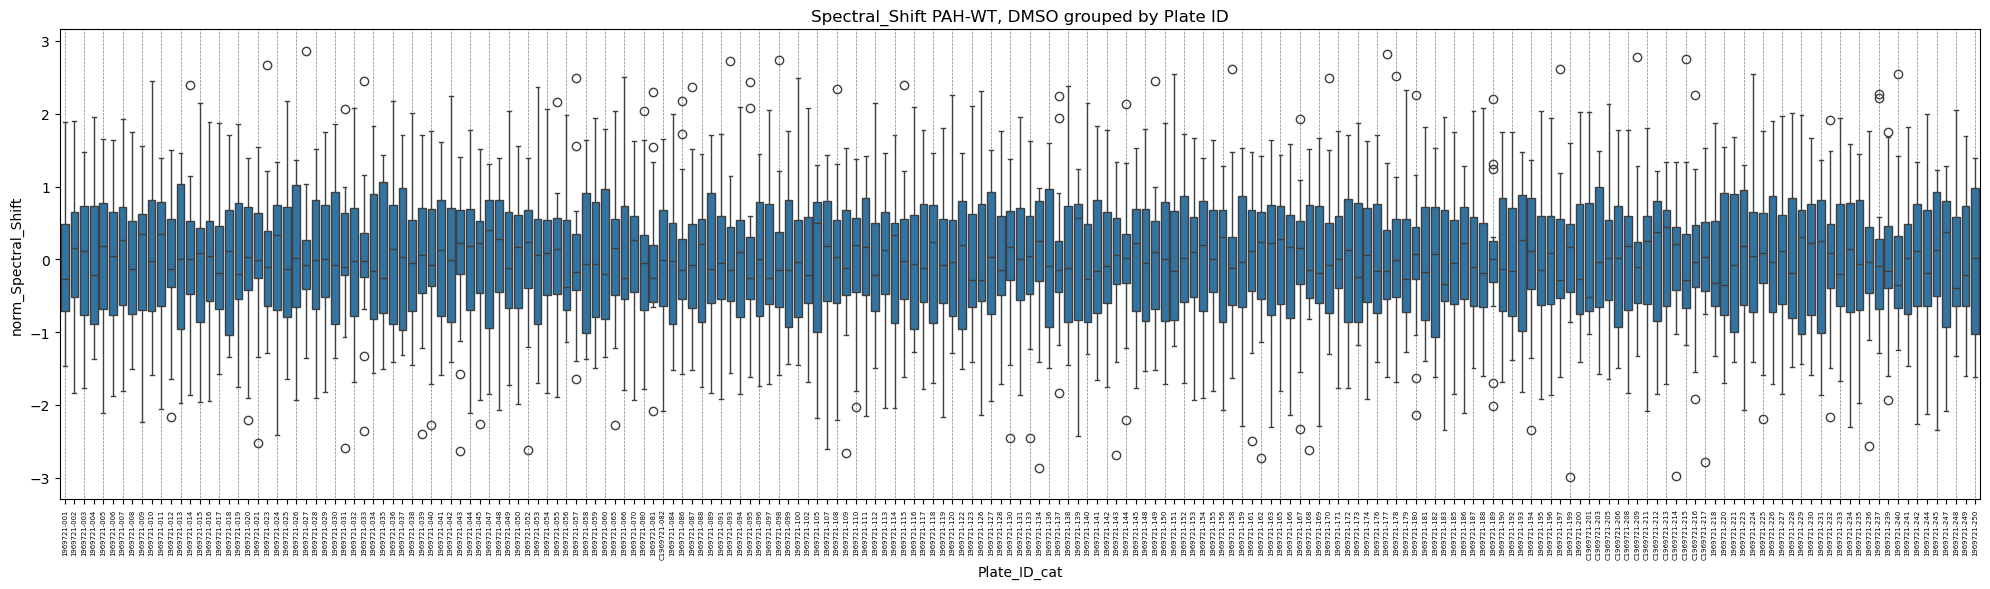

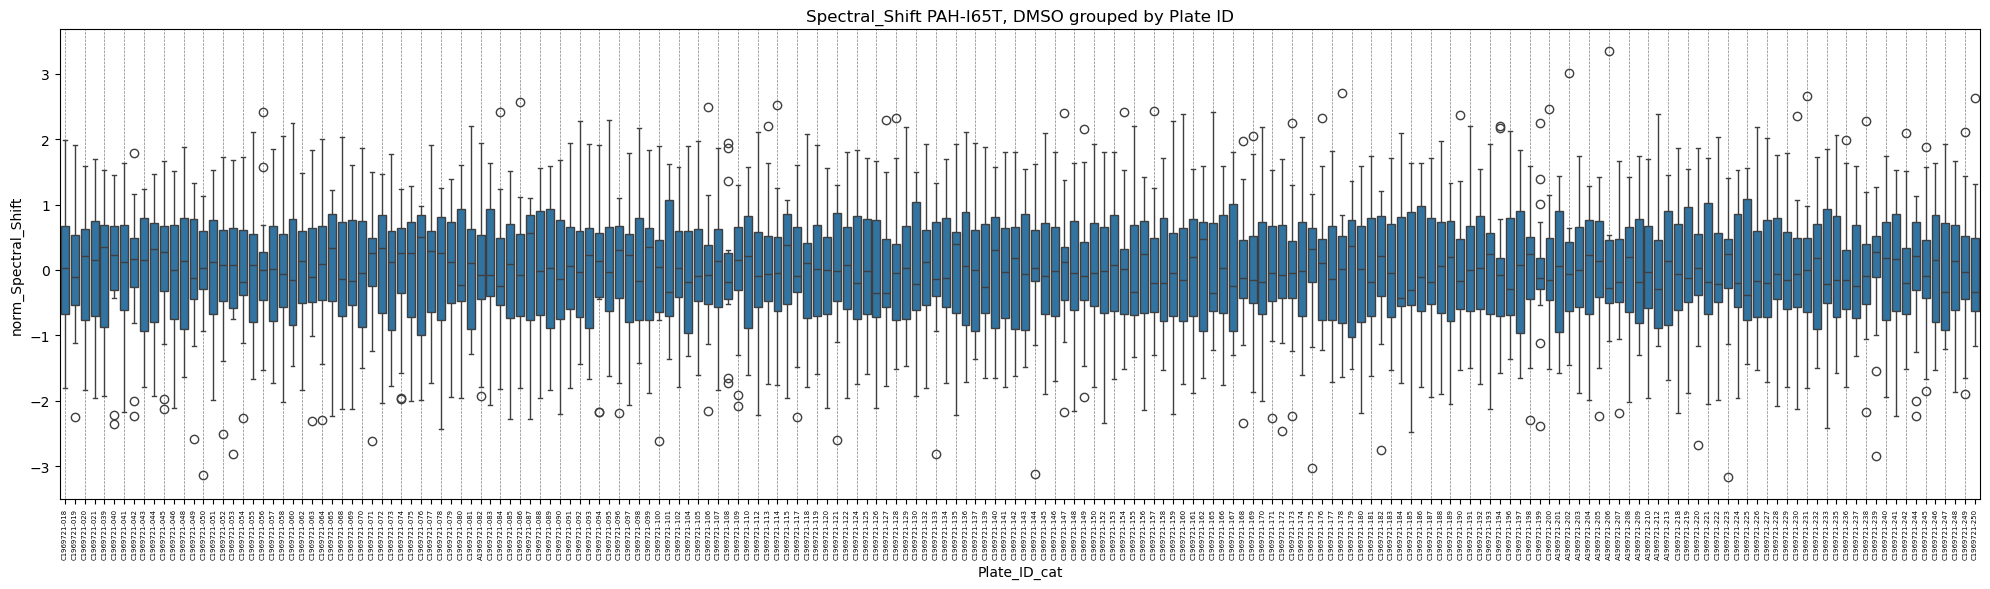

In [119]:
assey = ['Thermal_Shift', 'Spectral_Shift'][1]

# Plate-id orderes: 
# to see original order use Plate_ID
# to see them ordered based on numbers use Plate_ID_cat

# Restrict to a protein
# PAH-WT
plt.figure(figsize=(20, 6))

df_ctrl_prot = df_ctrl.loc[df_ctrl['Protein'] == 'PAH-WT'].copy()
df_ctrl_prot['Plate_ID_cat'] = df_ctrl_prot['Plate_ID_cat'].cat.remove_unused_categories()

n_plate = len(df_ctrl_prot['Plate_ID_cat'].unique())
plt.vlines(np.arange(0, n_plate, 2), ymin = -10, ymax = 10, colors='gray', linestyles='dashed', linewidth=0.5)
sns.boxplot(data=df_ctrl_prot, x='Plate_ID_cat', y=f'norm_{assey}')

plt.title(f'{assey} PAH-WT, DMSO grouped by Plate ID')
plt.xticks(rotation=90, size = 5)
plt.tight_layout()
# plt.savefig(f"data/plt_{assey}_DMSO_{save_tag}.pdf")
plt.show()
plt.close()

# Restrict to a protein
# PAH-I65T

plt.figure(figsize=(20, 6))

df_ctrl_prot = df_ctrl.loc[df_ctrl['Protein'] == 'PAH-I65T'].copy()
df_ctrl_prot['Plate_ID_cat'] = df_ctrl_prot['Plate_ID_cat'].cat.remove_unused_categories()

n_plate = len(df_ctrl_prot['Plate_ID_cat'].unique())
plt.vlines(np.arange(0, n_plate, 2), ymin = -10, ymax = 10, colors='gray', linestyles='dashed', linewidth=0.5)
sns.boxplot(data=df_ctrl_prot, x='Plate_ID_cat', y=f'norm_{assey}')

plt.title(f'{assey} PAH-I65T, DMSO grouped by Plate ID')
plt.xticks(rotation=90, size = 5)
plt.tight_layout()
# plt.savefig(f"data/plt_{assey}_I65T_DMSO_{save_tag}.pdf")
plt.show()
plt.close()

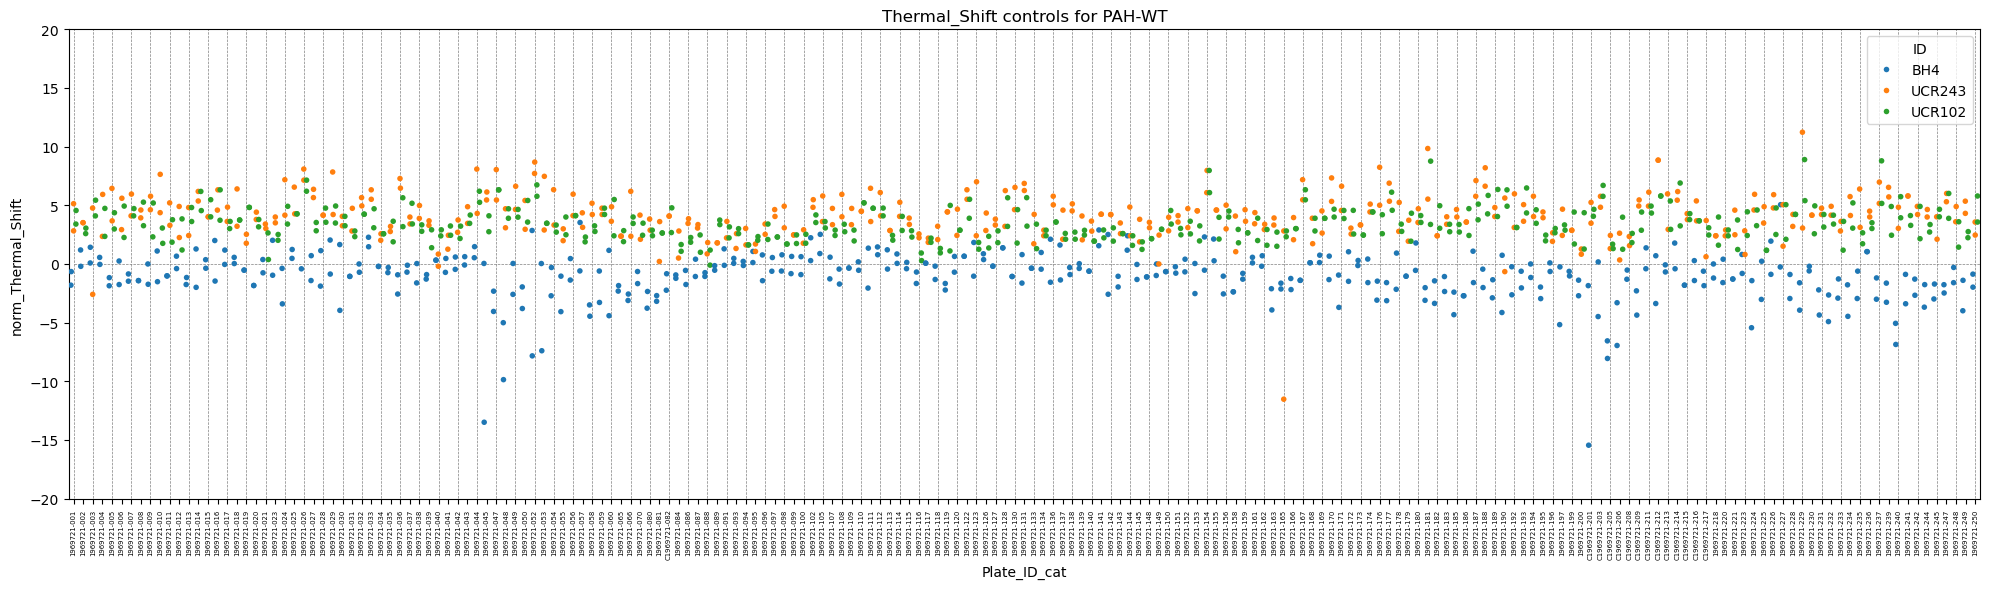

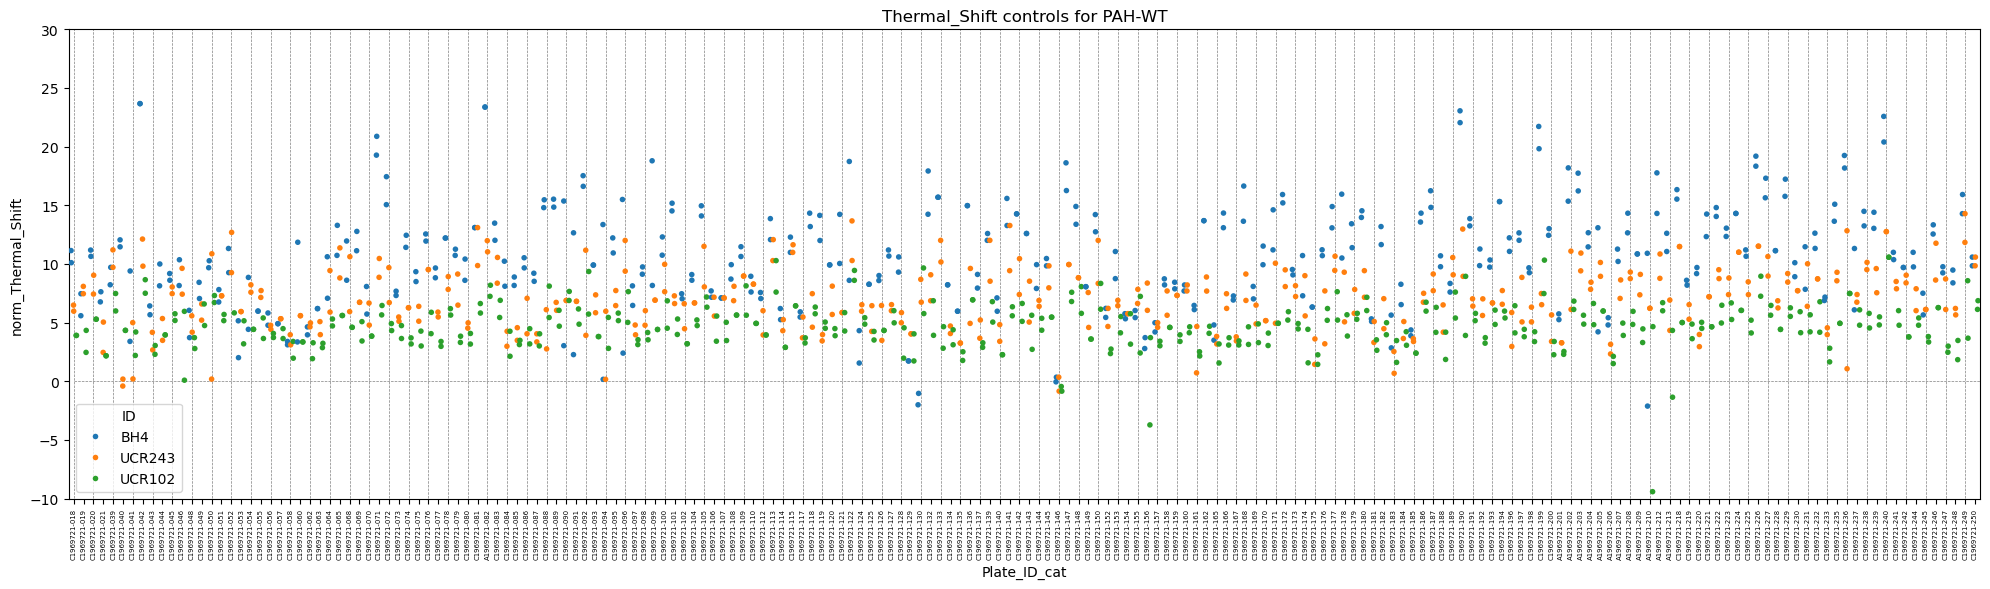

In [120]:
# Show controls only
assey = ['Thermal_Shift', 'Spectral_Shift'][0]

plt.figure(figsize=(20, 6))

df_other_prot = df_other.loc[df_other['Protein'] == 'PAH-WT'].copy()
df_other_prot['Plate_ID_cat'] = df_other_prot['Plate_ID_cat'].cat.remove_unused_categories()

n_plate = len(df_other_prot['Plate_ID_cat'].unique())

df_other_control = df_other_prot.loc[df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])]

plt.vlines(np.arange(0, n_plate, 2), ymin = -30, ymax = 30, colors='gray', linestyles='dashed', linewidth=0.5)
plt.hlines(0, xmin = 0, xmax = n_plate, colors='gray', linestyles='dashed', linewidth=0.5)

sns.stripplot(data=df_other_control, x='Plate_ID_cat', y=f'norm_{assey}', hue='ID', dodge=True, jitter=True, size=4)

plt.title(f'{assey} controls for PAH-WT')
plt.xticks(rotation=90, size = 5)
plt.ylim([-20, 20])
# plt.ylim([-2.5, 2.5])
plt.tight_layout()
# plt.savefig(f"data/plt_{assey}_control_norm_{save_tag}_PAH_WT.pdf")
plt.show()
plt.close()

# Show controls only
plt.figure(figsize=(20, 6))

df_other_prot = df_other.loc[df_other['Protein'] == 'PAH-I65T'].copy()
df_other_prot['Plate_ID_cat'] = df_other_prot['Plate_ID_cat'].cat.remove_unused_categories()

n_plate = len(df_other_prot['Plate_ID_cat'].unique())

df_other_control = df_other_prot.loc[df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])]

plt.vlines(np.arange(0, n_plate, 2), ymin = -30, ymax = 30, colors='gray', linestyles='dashed', linewidth=0.5)
plt.hlines(0, xmin = 0, xmax = n_plate, colors='gray', linestyles='dashed', linewidth=0.5)

sns.stripplot(data=df_other_control, x='Plate_ID_cat', y=f'norm_{assey}', hue='ID', dodge=True, jitter=True, size=4)

plt.title(f'{assey} controls for PAH-WT')
plt.xticks(rotation=90, size = 5)
plt.ylim([-10, 30])
# plt.ylim([-1, 3])
plt.tight_layout()
# plt.savefig(f"data/plt_{assey}_control_norm_{save_tag}_PAH_WT.pdf")
plt.show()
plt.close()

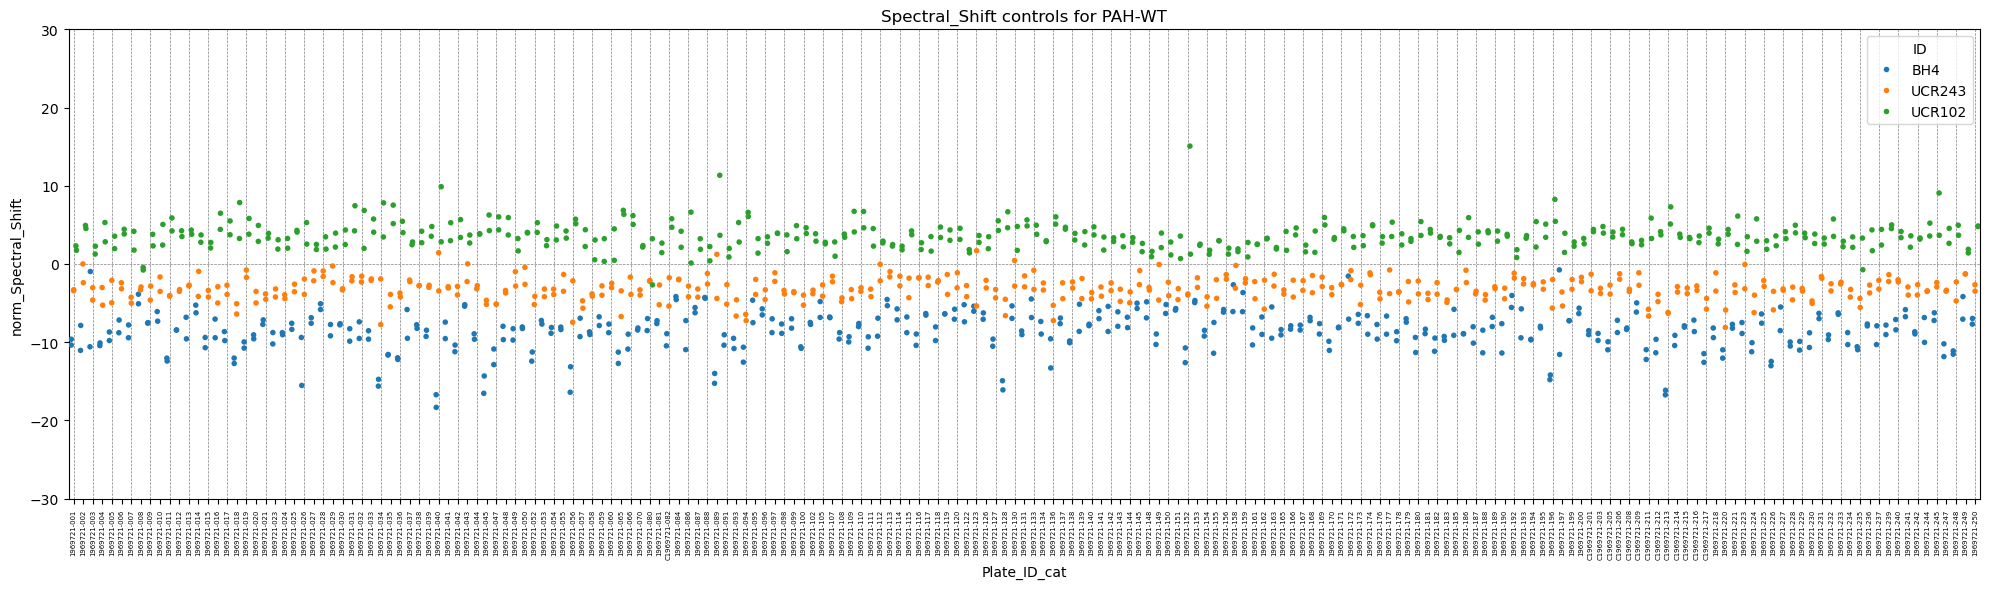

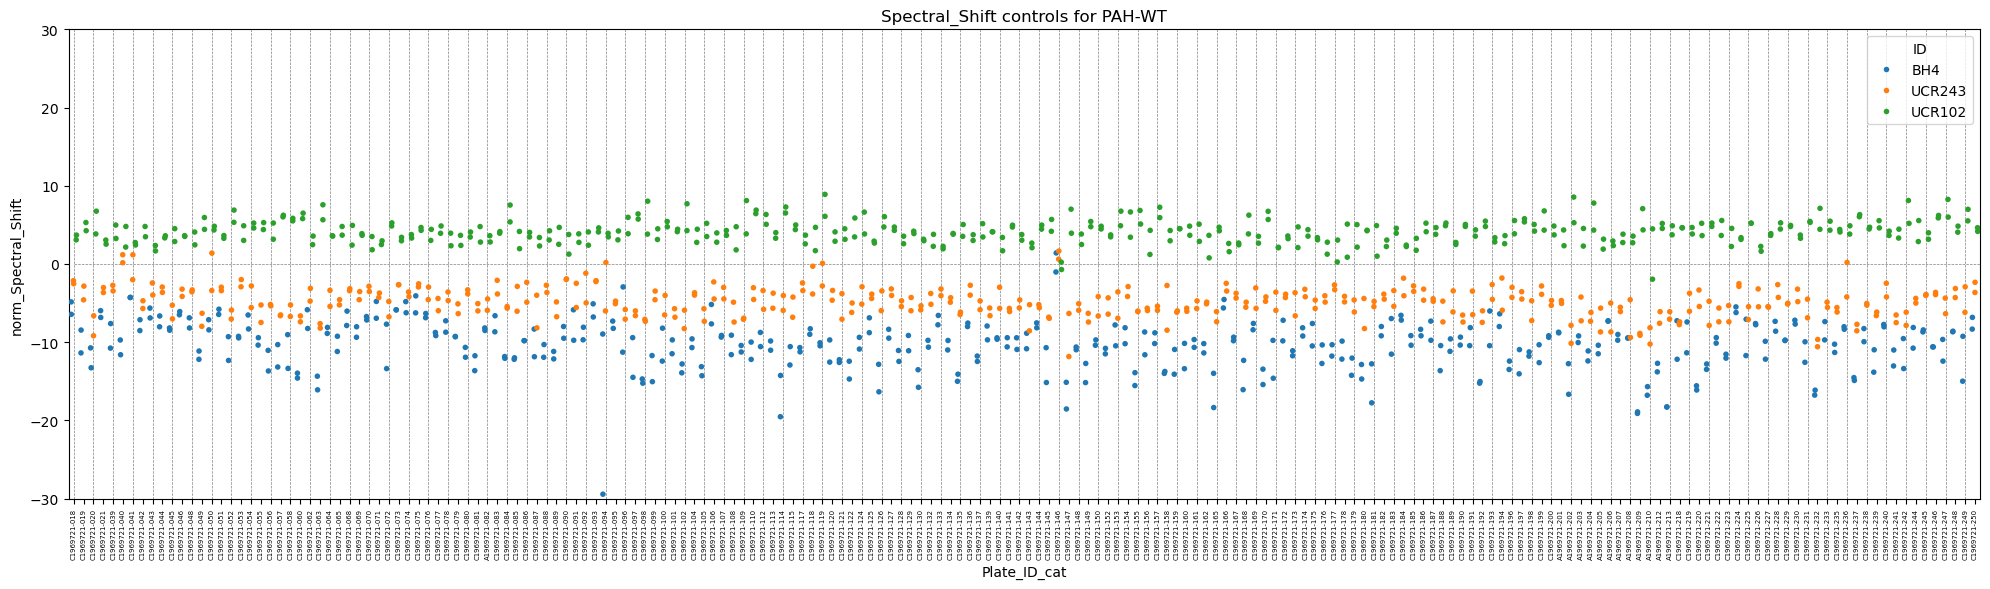

In [121]:
# Show controls only
assey = ['Thermal_Shift', 'Spectral_Shift'][1]

plt.figure(figsize=(20, 6))

df_other_prot = df_other.loc[df_other['Protein'] == 'PAH-WT'].copy()
df_other_prot['Plate_ID_cat'] = df_other_prot['Plate_ID_cat'].cat.remove_unused_categories()

n_plate = len(df_other_prot['Plate_ID_cat'].unique())

df_other_control = df_other_prot.loc[df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])]

plt.vlines(np.arange(0, n_plate, 2), ymin = -30, ymax = 30, colors='gray', linestyles='dashed', linewidth=0.5)
plt.hlines(0, xmin = 0, xmax = n_plate, colors='gray', linestyles='dashed', linewidth=0.5)

sns.stripplot(data=df_other_control, x='Plate_ID_cat', y=f'norm_{assey}', hue='ID', dodge=True, jitter=True, size=4)

plt.title(f'{assey} controls for PAH-WT')
plt.xticks(rotation=90, size = 5)
plt.ylim([-30, 30])
#plt.ylim([-1, 1])
plt.tight_layout()
# plt.savefig(f"data/plt_{assey}_control_norm_{save_tag}_PAH_WT.pdf")
plt.show()
plt.close()

# Show controls only
plt.figure(figsize=(20, 6))

df_other_prot = df_other.loc[df_other['Protein'] == 'PAH-I65T'].copy()
df_other_prot['Plate_ID_cat'] = df_other_prot['Plate_ID_cat'].cat.remove_unused_categories()

n_plate = len(df_other_prot['Plate_ID_cat'].unique())

df_other_control = df_other_prot.loc[df_other['ID'].isin(['BH4', 'UCR243', 'UCR102'])]

plt.vlines(np.arange(0, n_plate, 2), ymin = -30, ymax = 30, colors='gray', linestyles='dashed', linewidth=0.5)
plt.hlines(0, xmin = 0, xmax = n_plate, colors='gray', linestyles='dashed', linewidth=0.5)

sns.stripplot(data=df_other_control, x='Plate_ID_cat', y=f'norm_{assey}', hue='ID', dodge=True, jitter=True, size=4)

plt.title(f'{assey} controls for PAH-WT')
plt.xticks(rotation=90, size = 5)
plt.ylim([-30, 30])
plt.tight_layout()
# plt.savefig(f"data/plt_{assey}_control_norm_{save_tag}_PAH_WT.pdf")
plt.show()
plt.close()